# Implementando makemore: modelo de **trigramas**

> Continuación natural de `makemore_bigramas_probabilisticos.ipynb`.
> Mismo dataset, mismo vocabulario, mismas herramientas. Lo único que cambia es **cuánto contexto mira el modelo**.

## 🎯 Objetivo de este notebook

En el notebook de bigramas el modelo miraba **un** caracter para predecir el siguiente:

$$P(c_3 \mid c_2)$$

Acá vamos a mirar **dos** caracteres para predecir el tercero:

$$P(c_3 \mid c_1, c_2)$$

Y vamos a responder experimentalmente una pregunta concreta:

> **¿Baja la Negative Log Likelihood (NLL) al usar dos caracteres de contexto en lugar de uno?**

## 🗺️ Plan de trabajo

Construimos **dos modelos de trigramas**, y nada más que eso, para poder seguir cada operación en detalle:

1. Cargar **el mismo** dataset de 100.000 nombres de ciudades y reconstruir el vocabulario de 40 caracteres (`charset`, `ctoi`, `itoc`).
2. Entender qué cambia entre bigramas y trigramas (probabilidad condicional + hipótesis de Markov).
3. Separar **train / test por nombre**, para poder hablar de generalización y no engañarnos.
4. **Modelo 1 — trigrama estadístico:** por conteos, en un tensor de `40 x 40 x 40`, con *Laplace smoothing*.
5. **Modelo 2 — trigrama neuronal lineal:** dos One-Hot concatenados (80 entradas) y una capa de 40 neuronas, entrenada con descenso por gradiente.
6. Comparar los dos contra el **modelo uniforme** con la misma métrica y las mismas particiones.
7. Generar nombres de ciudades con cada modelo.
8. Conclusiones honestas: qué mejoró, qué no, y por qué.

> 💡 **Regla del notebook:** nada de Transformers, *embeddings* ni atención. Solo matrices, tensores y operaciones matemáticas que podemos escribir a mano.

## 1. Preparación: librerías

Usamos exactamente las mismas librerías del notebook original.

- **NumPy:** arrays y operaciones vectorizadas (para el modelo estadístico por conteos).
- **PyTorch:** tensores + *autograd* (la derivación automática que nos permite entrenar la red).
- **Matplotlib:** gráficos (mapas de calor y curvas de pérdida).

In [1]:
import numpy as np                  # NumPy: arrays N-dimensionales y operaciones vectorizadas (sin bucles de Python)
import torch                          # PyTorch: tensores + autograd (calcula gradientes automaticamente)
import torch.nn.functional as F       # Funciones sueltas de PyTorch: one_hot, cross_entropy, softmax...
import matplotlib.pyplot as plt       # Graficos
import time                           # Para medir cuanto tarda el entrenamiento

# Dejamos registrado con que versiones corrio el notebook
print('numpy :', np.__version__)
print('torch :', torch.__version__)

numpy : 2.5.3
torch : 2.14.1+cpu


## 2. El mismo dataset de siempre

Repetimos **literalmente** la carga del notebook de bigramas, para que los resultados sean comparables:

1. Leemos `data/city_names_puny.txt`.
2. Descartamos los nombres codificados en *punycode* (los que contienen `xn--`).
3. Fijamos la semilla `np.random.seed(42)` y tomamos **100.000 nombres al azar sin repetición**.

> ⚠️ **Por qué importa la semilla:** `seed(42)` hace que `np.random.choice` devuelva *exactamente* la misma muestra que en el notebook original. Si la cambiáramos, cambiaría el dataset y las NLL ya no serían comparables con las del notebook de bigramas.

In [2]:
# open(...).read()  -> lee TODO el archivo como un unico string
# .split('\n')      -> lo corta en una lista, un nombre de ciudad por linea
dataset = open('data/city_names_puny.txt', 'r').read().split('\n')

# Separamos los nombres en punycode (empiezan con 'xn--') de los "normales".
# punycode es una codificacion ASCII para texto no-ASCII (acentos, otros alfabetos).
puny   = [x for x in dataset if 'xn--' in x]        # codificados (los descartamos)
nopuny = [x for x in dataset if 'xn--' not in x]    # ASCII simple (los que usamos)

print('nombres totales :', len(dataset))
print('nombres no-puny :', len(nopuny))

nombres totales : 143844
nombres no-puny : 116635


In [3]:
# Fijamos la semilla del generador aleatorio de NumPy para que la muestra sea REPRODUCIBLE.
# Es la MISMA semilla (42) del notebook de bigramas -> obtenemos EL MISMO dataset.
np.random.seed(42)

# np.random.choice(lista, n, replace=False) -> elige n elementos al azar SIN repetir.
# Devuelve objetos de numpy; .item() los convierte a strings de Python normales.
dataset = [x.item() for x in np.random.choice(nopuny, 100000, replace=False)]

print('nombres elegidos :', len(dataset))
print('primeros 10      :', dataset[:10])
print('dataset[3]       :', dataset[3], '  <- lo usamos como ejemplo en todo el notebook')

nombres elegidos : 100000
primeros 10      : ['kotamangalam', 'fredepo', 'la trinidad', 'bojia', 'langayo', 'cape coral', 'jerzens', 'aleksandrovskiy zavod', 'damian carmona', 'yongping']
dataset[3]       : bojia   <- lo usamos como ejemplo en todo el notebook


### 2.1 El vocabulario: `charset`, `ctoi`, `itoc`

Reutilizamos la misma construcción del notebook original:

- `charset`: la lista ordenada de caracteres. Ponemos `'*'` **primero** (índice 0) y después el resto ordenado alfabéticamente.
- `ctoi` (*char to index*): diccionario caracter → número. Lo necesitamos porque los tensores se indexan con enteros, no con letras.
- `itoc` (*index to char*): el diccionario inverso, número → caracter. Lo usamos para "traducir" de vuelta lo que genera el modelo.

El `'*'` es el **marcador especial** de inicio y fin de palabra. Antes de usarlo verificamos que no aparezca en ningún nombre real: si apareciera, el modelo confundiría una letra real con "fin de palabra".

In [4]:
# Verificamos que '*' NO sea un caracter real del dataset.
# set([y for x in dataset for y in x]) -> conjunto de TODOS los caracteres distintos que aparecen.
# Esperamos que imprima False.
print("'*' aparece en algun nombre?:", '*' in set([y for x in dataset for y in x]))

'*' aparece en algun nombre?: False


In [5]:
# charset = vocabulario ORDENADO: '*' en el indice 0, y luego el resto alfabeticamente.
charset = ['*'] + sorted(list(set([y for x in dataset for y in x])))

# ctoi: 'char to index'  -> {'*': 0, ' ': 1, '-': 2, ..., 'a': 14, ...}
ctoi = {c: i for i, c in enumerate(charset)}
# itoc: 'index to char'  -> el mapeo inverso {0: '*', 1: ' ', ...}
itoc = {i: c for i, c in enumerate(charset)}

# nclasses = tamano del vocabulario. Es la cantidad de "clases" que el modelo puede predecir.
# Lo llamamos igual que en el notebook original.
nclasses = len(charset)

print('tamano del vocabulario (nclasses):', nclasses)
print('charset:', charset)

tamano del vocabulario (nclasses): 40
charset: ['*', ' ', '-', '.', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']


## 3. ¿Qué es un modelo de trigramas?

### 3.1 Probabilidad condicional

Un **modelo de lenguaje** asigna una probabilidad a cada caracter posible, *dado* lo que vino antes. Eso es una **probabilidad condicional**: la probabilidad de un evento sabiendo que otro ya ocurrió.

$$P(A \mid B) = \frac{P(A, B)}{P(B)}$$

Se lee "probabilidad de $A$ **dado** $B$". En nuestro caso $B$ es el contexto (los caracteres anteriores) y $A$ es el caracter que queremos predecir.

Si la estimamos **contando**, la fórmula se vuelve muy concreta. Para el bigrama era:

$$P(c_3 \mid c_2) \approx \frac{\#(c_2, c_3)}{\#(c_2, \cdot)} = \frac{\text{veces que } c_2 \text{ fue seguido por } c_3}{\text{veces que apareció } c_2 \text{ como contexto}}$$

Eso es **exactamente** lo que hacía `bigram_count / bigram_count.sum(axis=1, keepdims=True)`: dividir cada fila por su total.

Para el trigrama es la misma idea, pero el contexto son **dos** caracteres:

$$\boxed{P(c_3 \mid c_1, c_2) \approx \frac{\#(c_1, c_2, c_3)}{\#(c_1, c_2, \cdot)}}$$

### 3.2 La hipótesis de Markov

Lo correcto, en teoría, sería modelar la probabilidad del próximo caracter dada **toda** la historia:

$$P(c_n \mid c_1, c_2, \dots, c_{n-1})$$

Pero eso es imposible de estimar por conteo: la cantidad de historias posibles crece como $40^{n-1}$. Con 10 caracteres de contexto serían $40^{10} \approx 10^{16}$ combinaciones, y solo tenemos un millón de ejemplos.

La **hipótesis de Markov** es la simplificación que nos salva: *suponemos que solo importan los últimos $k$ caracteres*.

| Modelo | Hipótesis | Lo que mira | Parámetros |
|---|---|---|---|
| Uniforme | nada importa | — | 0 |
| Bigrama | Markov de orden **1** | $P(c_3 \mid c_2)$ | $40 \times 40 = 1.600$ |
| **Trigrama** | Markov de orden **2** | $P(c_3 \mid c_1, c_2)$ | $40 \times 40 \times 40 = 64.000$ |

### 3.3 El *trade-off* central del experimento

Pasar de bigrama a trigrama tiene dos efectos **opuestos**:

- ✅ **A favor:** el modelo puede representar reglas más específicas. Un bigrama solo sabe "después de `q` suele venir `u`". Un trigrama puede saber "después de `an` suele venir `d`" (*santander*, *andes*...), algo que el bigrama **no puede expresar** porque ya se olvidó de la `a`.
- ❌ **En contra:** multiplicamos los parámetros por 40 (de 1.600 a 64.000) pero **la cantidad de datos sigue siendo la misma**. Muchas combinaciones de dos caracteres van a aparecer pocas veces, o ninguna. Eso se llama **dispersión de datos** (*data sparsity*) y es la principal fuente de **sobreajuste** (*overfitting*).

Por eso el experimento es interesante: la mejora **no está garantizada**. Vamos a medirla.

### 3.4 Construyendo las secuencias: ¿por qué **dos** marcadores de inicio y **uno** de fin?

Recordemos el bigrama: a cada nombre le poníamos `'*' + nombre + '*'`. Un marcador adelante (para aprender con qué caracter *empiezan* las palabras) y uno atrás (para aprender cuándo *terminan*).

Para el trigrama necesitamos `'**' + nombre + '*'`. La razón es puramente estructural:

**¿Por qué DOS al inicio?** Porque el trigrama necesita **siempre dos caracteres de contexto** para predecir. Para predecir el **primer** caracter real del nombre no hay nada antes, así que rellenamos con dos `*`: el contexto `(*, *)` significa literalmente "estoy arrancando una palabra desde cero". Para predecir el **segundo** caracter real tenemos un solo caracter de historia, así que el contexto es `(*, primer_caracter)`.

**¿Por qué UNO solo al final?** Porque el `*` final no es contexto: es un **objetivo a predecir**. Es la forma que tiene el modelo de decir "acá se termina la palabra". Con un solo marcador alcanza: cuando el modelo lo genera, paramos.

Veámoslo con `bojia`:

| # | Carácter 1 | Carácter 2 | Objetivo |
|---|---|---|---|
| 0 | `*` | `*` | `b` |
| 1 | `*` | `b` | `o` |
| 2 | `b` | `o` | `j` |
| 3 | `o` | `j` | `i` |
| 4 | `j` | `i` | `a` |
| 5 | `i` | `a` | `*` |

> 🔑 **Dato clave:** un nombre de longitud $L$ produce $L+1$ ejemplos, **igual que en el bigrama** (`bojia` tiene 5 letras → 6 ejemplos en los dos casos). Esto es importante porque significa que el trigrama predice **exactamente el mismo conjunto de caracteres objetivo** que predecía el bigrama, incluido el marcador de fin. Por eso la *NLL promedio por caracter predicho* que vamos a calcular es directamente comparable con la del notebook anterior.

In [6]:
# Igual que el notebook original usaba zip(d, d[1:]) para bigramas,
# para trigramas usamos zip(ex, ex[1:], ex[2:]): agrupamos cada caracter con los DOS siguientes.
#   ex       -> *  *  b  o  j  i  a  *
#   ex[1:]   -> *  b  o  j  i  a  *
#   ex[2:]   -> b  o  j  i  a  *
# zip() corta en el mas corto, asi que obtenemos las tripletas (c1, c2, objetivo).

d = dataset[3]                      # 'bojia'
ex = ['*', '*'] + list(d) + ['*']   # DOS marcadores al inicio, UNO al final

print('nombre:', d)
print('secuencia con marcadores:', ''.join(ex))
print()
print(' #  c1  c2  ->  objetivo')
print('-' * 28)
for i, (c1, c2, y) in enumerate(zip(ex, ex[1:], ex[2:])):
    print(f' {i}   {c1}   {c2}   ->     {y}')

# len(ex) - 2 ejemplos = len(d) + 1 -> la misma cantidad que daba el bigrama
print()
print(f'ejemplos generados: {len(ex) - 2}  =  len("{d}") + 1 = {len(d) + 1}')

nombre: bojia
secuencia con marcadores: **bojia*

 #  c1  c2  ->  objetivo
----------------------------
 0   *   *   ->     b
 1   *   b   ->     o
 2   b   o   ->     j
 3   o   j   ->     i
 4   j   i   ->     a
 5   i   a   ->     *

ejemplos generados: 6  =  len("bojia") + 1 = 6


## 4. Separar entrenamiento y prueba (**antes** de construir los ejemplos)

### ¿Qué problema resuelve?

Si midiéramos la NLL solo sobre los datos con los que entrenamos, un modelo con muchos parámetros **siempre** ganaría: puede "memorizar" mejor. Pero memorizar no es aprender. Lo que nos interesa es la **generalización**: qué tan bien le va con nombres que **nunca vio**.

- **NLL de entrenamiento** baja + **NLL de prueba** baja → el modelo aprendió patrones reales. ✅
- **NLL de entrenamiento** baja + **NLL de prueba** alta → **sobreajuste**: memorizó el ruido del conjunto de entrenamiento. ❌

Esto es especialmente importante acá, porque el trigrama tiene 40 veces más parámetros que el bigrama con los mismos datos.

### ¿Por qué separar **por nombre** y no por ejemplo?

Porque si partiéramos las ~1.000.000 de tripletas al azar, las tripletas de `kotamangalam` quedarían repartidas entre *train* y *test*. El modelo habría visto la mayor parte del nombre durante el entrenamiento y el test estaría **contaminado** (*data leakage*): mediríamos memorización disfrazada de generalización. Separando por nombre garantizamos que **ningún nombre aparece en los dos conjuntos**.

### ⚠️ Una trampa real del dataset: hay nombres **repetidos**

Acá hay que tener cuidado con algo que es fácil pasar por alto. El primer intento natural sería mezclar los índices del dataset y cortar al 90%:

```python
perm = rng.permutation(len(dataset))
train_names = [dataset[i] for i in perm[:n_train]]
test_names  = [dataset[i] for i in perm[n_train:]]
```

Pero eso **no funciona** con este dataset, y conviene entender por qué. Hay muchísimas ciudades **homónimas**: `san francisco` aparece 40 veces, `san antonio` 39, `santa cruz` 35... En total, de las 100.000 entradas solo **87.723 son nombres distintos**.

Si cortáramos por posición, `san francisco` caería con casi total seguridad en los dos conjuntos a la vez. El modelo lo vería 36 veces durante el entrenamiento y después lo encontraría en el test: mediríamos **memorización pura**. Es exactamente el *data leakage* que queríamos evitar, entrando por una puerta lateral.

### La partición correcta

El arreglo es partir la lista de nombres **únicos**, y después repartir las ocurrencias según de qué lado cayó cada nombre:

1. `nombres_unicos = sorted(set(dataset))` → los 87.723 nombres distintos.
   - El `sorted()` no es cosmético: el orden de iteración de un `set` de strings **depende del hash de Python**, que cambia entre ejecuciones. Sin ordenar, la partición no sería reproducible.
2. Mezclar esos nombres únicos y cortar al 90%.
3. Mandar **todas** las ocurrencias de cada nombre al conjunto que le toca.

Así conservamos las 100.000 entradas (las repeticiones son información legítima de frecuencia: que `san francisco` sea un nombre común es un patrón real que el modelo debe aprender) y al mismo tiempo garantizamos que **ningún nombre aparece en los dos conjuntos**.

Usamos un `RandomState` propio con semilla `1234` en lugar de `np.random.seed`, para no alterar el estado del generador global que ya usamos al elegir el dataset.

In [7]:
# Primero constatamos el problema: cuantos nombres REPETIDOS hay en el dataset.
import collections   # Counter: cuenta cuantas veces aparece cada elemento de una lista

conteo_nombres = collections.Counter(dataset)

print('entradas totales  :', len(dataset))
print('nombres distintos :', len(conteo_nombres))
print('entradas repetidas:', len(dataset) - len(conteo_nombres))
print()
print('los nombres mas repetidos (ciudades homonimas):')
for nombre, veces in conteo_nombres.most_common(6):
    print(f'  {nombre:<16} x{veces}')
print()
print('=> No podemos partir por posicion: un nombre repetido caeria en los dos conjuntos.')

entradas totales  : 100000
nombres distintos : 87723
entradas repetidas: 12277

los nombres mas repetidos (ciudades homonimas):
  san francisco    x40
  san antonio      x39
  san isidro       x37
  santa cruz       x35
  buenavista       x32
  santa ana        x29

=> No podemos partir por posicion: un nombre repetido caeria en los dos conjuntos.


In [8]:
# np.random.RandomState(1234): generador aleatorio INDEPENDIENTE, con su propia semilla.
# Lo usamos para no "mover" el generador global de numpy (el del seed(42) de arriba).
rng = np.random.RandomState(1234)

# 1) Lista de nombres UNICOS. sorted() es imprescindible: el orden de un set de strings
#    depende del hash de Python y cambia entre ejecuciones -> sin ordenar no seria reproducible.
nombres_unicos = sorted(set(dataset))

# 2) Mezclamos los nombres unicos y cortamos al 90%.
#    .permutation(n) -> array con los numeros 0..n-1 en orden aleatorio.
perm = rng.permutation(len(nombres_unicos))
n_train = int(0.9 * len(nombres_unicos))

# Usamos conjuntos (set) y no listas porque el "in" de un set es instantaneo (tabla hash),
# mientras que en una lista habria que recorrerla entera: con 87.723 nombres la diferencia es enorme.
set_train = set(nombres_unicos[i] for i in perm[:n_train])
set_test  = set(nombres_unicos[i] for i in perm[n_train:])

# 3) Repartimos TODAS las ocurrencias segun de que lado cayo cada nombre.
train_names = [d for d in dataset if d in set_train]
test_names  = [d for d in dataset if d in set_test]

print('nombres unicos          :', len(nombres_unicos))
print('  -> unicos en train    :', len(set_train))
print('  -> unicos en test     :', len(set_test))
print()
print('entradas de entrenamiento:', len(train_names))
print('entradas de prueba       :', len(test_names))
print('total (sin perder nada)  :', len(train_names) + len(test_names))
print()

# VERIFICACION CLAVE: la interseccion de los dos conjuntos debe estar vacia.
# set(a) & set(b) -> interseccion de conjuntos.
solapados = set(train_names) & set(test_names)
print('nombres en AMBOS conjuntos:', len(solapados), '(debe ser 0)')
assert len(solapados) == 0, 'hay fuga de datos entre train y test'

print()
print('ejemplos de train:', train_names[:4])
print('ejemplos de test :', test_names[:4])

nombres unicos          : 87723
  -> unicos en train    : 78950
  -> unicos en test     : 8773

entradas de entrenamiento: 89982
entradas de prueba       : 10018
total (sin perder nada)  : 100000

nombres en AMBOS conjuntos: 0 (debe ser 0)

ejemplos de train: ['kotamangalam', 'fredepo', 'la trinidad', 'bojia']
ejemplos de test : ['jalalpore', 'civitella di romagna', 'bath', 'braives']


### 4.1 Construyendo los tensores de ejemplos

Ahora convertimos los nombres en **índices numéricos**, igual que hacía el notebook original con `xs` e `ys`.

La diferencia es que el trigrama necesita **dos** tensores de entrada:

| Tensor | Qué guarda | Forma |
|---|---|---|
| `xs1` | índice del **primer** caracter de contexto | `(n,)` |
| `xs2` | índice del **segundo** caracter de contexto | `(n,)` |
| `ys` | índice del caracter **objetivo** | `(n,)` |

**¿Qué es un tensor?** Un array de números con una **forma** (*shape*):

- forma `(n,)` → un vector de `n` números (**1** dimensión).
- forma `(n, 40)` → una matriz de `n` filas y 40 columnas (**2** dimensiones).
- forma `(40, 40, 40)` → un "cubo" de números (**3** dimensiones).

Llevar la cuenta de las formas es la mitad del trabajo al programar redes neuronales, así que las vamos a imprimir todo el tiempo.

In [9]:
def build_trigramas(names):
    """Convierte una lista de nombres en los tensores (xs1, xs2, ys) del modelo de TRIGRAMAS.

    xs1[i], xs2[i] = indices de los DOS caracteres de contexto
    ys[i]          = indice del caracter a predecir
    """
    xs1, xs2, ys = [], [], []
    for d in names:
        ex = ['*', '*'] + list(d) + ['*']           # DOS marcadores adelante, uno atras
        for c1, c2, y in zip(ex, ex[1:], ex[2:]):   # cada caracter con los DOS siguientes
            xs1.append(ctoi[c1])                    # ctoi: traducimos caracter -> indice entero
            xs2.append(ctoi[c2])
            ys.append(ctoi[y])
    # torch.tensor(lista) convierte la lista de Python en un tensor de PyTorch (dtype int64).
    return torch.tensor(xs1), torch.tensor(xs2), torch.tensor(ys)

In [10]:
t0 = time.time()

# Construimos los ejemplos de cada conjunto por separado.
# Importante: el split ya esta hecho, asi que ninguna tripleta de un nombre de test
# puede aparecer en train.
x1_tr, x2_tr, y_tr = build_trigramas(train_names)
x1_te, x2_te, y_te = build_trigramas(test_names)

print(f'construido en {time.time() - t0:.1f}s')
print()
print('--- FORMAS DE LOS TENSORES ---')
print('train: xs1', tuple(x1_tr.shape), 'xs2', tuple(x2_tr.shape), 'ys', tuple(y_tr.shape))
print('test : xs1', tuple(x1_te.shape), 'xs2', tuple(x2_te.shape), 'ys', tuple(y_te.shape))
print('dtype:', x1_tr.dtype, '(int64: son INDICES, no probabilidades)')
print()

# VERIFICACION: los tres tensores de un conjunto deben tener la misma longitud
# (un contexto c1, un contexto c2 y un objetivo por ejemplo).
assert x1_tr.shape == x2_tr.shape == y_tr.shape
assert x1_te.shape == x2_te.shape == y_te.shape

# Y la cantidad total debe ser sum(len(nombre) + 1), como demostramos con 'bojia'.
esperado_tr = sum(len(d) + 1 for d in train_names)
assert len(y_tr) == esperado_tr, 'la cantidad de ejemplos no coincide con sum(len+1)'
print('OK: cantidad de ejemplos = suma de (longitud del nombre + 1)')
print(f'    caracteres a predecir en train: {len(y_tr):,}')
print(f'    caracteres a predecir en test : {len(y_te):,}')

construido en 0.8s

--- FORMAS DE LOS TENSORES ---
train: xs1 (942116,) xs2 (942116,) ys (942116,)
test : xs1 (104713,) xs2 (104713,) ys (104713,)
dtype: torch.int64 (int64: son INDICES, no probabilidades)

OK: cantidad de ejemplos = suma de (longitud del nombre + 1)
    caracteres a predecir en train: 942,116
    caracteres a predecir en test : 104,713


In [11]:
# Mirada rapida a los primeros 8 ejemplos de train, "traducidos" de vuelta a caracteres con itoc.
# Sirve para confirmar que los tensores quedaron bien armados.
print('primer nombre de train:', train_names[0])
print('con marcadores        :', '**' + train_names[0] + '*')
print()
print('idx | indices (c1, c2 -> y) | caracteres')
print('-' * 46)
for i in range(8):
    i1 = x1_tr[i].item()        # .item() saca el numero de Python de un tensor de 1 elemento
    i2 = x2_tr[i].item()
    iy = y_tr[i].item()
    print(f' {i}  |      ({i1:>2}, {i2:>2}) -> {iy:>2}       |   ({itoc[i1]}, {itoc[i2]}) -> {itoc[iy]}')

primer nombre de train: kotamangalam
con marcadores        : **kotamangalam*

idx | indices (c1, c2 -> y) | caracteres
----------------------------------------------
 0  |      ( 0,  0) -> 24       |   (*, *) -> k
 1  |      ( 0, 24) -> 28       |   (*, k) -> o
 2  |      (24, 28) -> 33       |   (k, o) -> t
 3  |      (28, 33) -> 14       |   (o, t) -> a
 4  |      (33, 14) -> 26       |   (t, a) -> m
 5  |      (14, 26) -> 14       |   (a, m) -> a
 6  |      (26, 14) -> 27       |   (m, a) -> n
 7  |      (14, 27) -> 20       |   (a, n) -> g


## 5. La métrica: Negative Log Likelihood (NLL)

Antes de construir cualquier modelo, fijemos **cómo lo vamos a medir**. Es el mismo razonamiento del notebook de bigramas, pero lo repetimos porque es el corazón del experimento.

### 5.1 De la verosimilitud a la pérdida

**1. Likelihood (verosimilitud).** Para una palabra, multiplicamos las probabilidades que el modelo le asigna a cada caracter que realmente ocurrió:

$$ \text{Likelihood} = \prod_{i} P(c_{i} \mid \text{contexto}_i) $$

Si el modelo es bueno, le da probabilidad alta a lo que realmente pasa y este producto es grande.

**2. Log-likelihood.** Multiplicar un millón de números entre 0 y 1 da un resultado tan diminuto que la computadora lo redondea a 0 (*underflow*). Aplicamos **logaritmo**, que convierte el producto en una **suma**:

$$ \log(\text{Likelihood}) = \sum_{i} \log P(c_{i} \mid \text{contexto}_i) $$

**3. Negative Log-Likelihood.** El logaritmo de un número entre 0 y 1 es negativo. Le cambiamos el signo (para tener un número positivo **a minimizar**) y lo promediamos por la cantidad de caracteres predichos $n$:

$$ \boxed{\text{NLL} = -\frac{1}{n} \sum_{i=1}^{n} \log P(c_{i} \mid c_{1,i}, c_{2,i})} $$

### 5.2 Cómo leer el número

| NLL | Interpretación |
|---|---|
| $0$ | el modelo predice el caracter correcto con probabilidad 1 (imposible en la práctica) |
| **más bajo** | mejor: el modelo se "sorprende" menos con los datos reales ✅ |
| $-\log(1/40) \approx 3.6889$ | **modelo uniforme**: elegir al azar entre 40 caracteres. Nuestra línea de base a batir |
| **más alto** | peor que tirar los dados ❌ |

> 💡 **Intuición extra:** $e^{\text{NLL}}$ se llama **perplejidad** (*perplexity*) y se interpreta como "entre cuántos caracteres está dudando el modelo, en promedio". El modelo uniforme tiene perplejidad 40. Si logramos NLL = 2.4, la perplejidad es $e^{2.4} \approx 11$: el modelo redujo sus dudas de 40 opciones a 11.

### 5.3 Clave de la comparación: **por caracter predicho**

Siempre dividimos por `n` = la cantidad total de caracteres predichos, **incluyendo el marcador de fin**. Como vimos en la sección 3.4, el trigrama predice la misma cantidad de caracteres que predecía el bigrama, así que los valores son directamente comparables entre notebooks.

In [12]:
# La linea de base: el modelo UNIFORME, que le asigna 1/40 a cada caracter sin mirar nada.
# -log(1/40) es la NLL de ese modelo. Cualquier modelo que valga la pena debe dar MENOS que esto.
nll_uniforme = -np.log(1 / nclasses)

print(f'probabilidad uniforme     : 1/{nclasses} = {1 / nclasses:.4f}')
print(f'NLL del modelo uniforme   : {nll_uniforme:.4f}')
print(f'perplejidad (e^NLL)       : {np.exp(nll_uniforme):.1f}  <- "duda entre 40 caracteres"')

probabilidad uniforme     : 1/40 = 0.0250
NLL del modelo uniforme   : 3.6889
perplejidad (e^NLL)       : 40.0  <- "duda entre 40 caracteres"


## 6. Modelo 1: trigrama estadístico con un tensor de `40 x 40 x 40`

Empezamos por el modelo **por conteos**, igual que hizo el notebook original con los bigramas. Es el camino más directo y además completamente interpretable: podemos abrirlo y leer lo que aprendió.

### 6.1 ¿Por qué necesitamos **tres** dimensiones?

Una matriz de 40×40 solo puede indexarse con **dos** números: `C[contexto, objetivo]`. Pero ahora el contexto son **dos** caracteres, así que necesitamos **tres** índices: `C[c1, c2, objetivo]`.

Un tensor de 3 dimensiones es, visualmente, un **cubo** de números. Y hay una forma muy útil de verlo:

> El tensor `trigram_count` de `40 x 40 x 40` es una **pila de 40 matrices**.
> La "rodaja" `trigram_count[i]` es una matriz de 40×40 que dice: *"sabiendo que el primer caracter del contexto fue `itoc[i]`, ¿cuál es la tabla del resto?"*

| Dimensión | Índice | Significado | Tamaño |
|---|---|---|---|
| 0 | `c1` | primer caracter del contexto (el más viejo) | 40 |
| 1 | `c2` | segundo caracter del contexto (el más reciente) | 40 |
| 2 | `y` | caracter objetivo a predecir | 40 |

El valor `trigram_count[i, j, k]` = *cuántas veces apareció la secuencia* `itoc[i] itoc[j] itoc[k]`.

En total: $40^3 = 64.000$ celdas, contra las 1.600 que usaba el bigrama. **40 veces más parámetros con la misma cantidad de datos** — acá nace el problema de la dispersión.

### 6.2 Vectorizar el conteo con `np.add.at`

El notebook original recorría los bigramas con un bucle de Python. Acá usamos `np.add.at(C, (xs1, xs2, ys), 1)`, que hace lo mismo pero de una sola vez y en C: recorre las tripletas `(xs1[k], xs2[k], ys[k])` y suma 1 en esa celda. Es el equivalente vectorizado de:

```python
for k in range(len(ys)):
    C[xs1[k], xs2[k], ys[k]] += 1
```

⚠️ No sirve escribir `C[xs1, xs2, ys] += 1` directamente, porque la indexación "fancy" de NumPy **no acumula** cuando un índice se repite (y acá se repiten muchísimo): solo escribiría el valor una vez. `np.add.at` sí acumula.

In [13]:
# --- MODELO 1: TRIGRAMA ESTADISTICO ---

# 1) Tensor de conteos TRIDIMENSIONAL 40 x 40 x 40, inicializado en ceros.
#    eje 0 = c1 (contexto viejo), eje 1 = c2 (contexto reciente), eje 2 = y (objetivo)
#    Usamos float64 (el default de np.zeros) porque despues vamos a dividir para normalizar.
trigram_count = np.zeros((nclasses, nclasses, nclasses))

# 2) Contamos los trigramas de TRAIN. np.add.at acumula +1 en la celda de cada ejemplo.
#    .numpy() convierte el tensor de PyTorch a array de NumPy (comparten memoria, no copia).
np.add.at(trigram_count,
          (x1_tr.numpy(), x2_tr.numpy(), y_tr.numpy()),
          1)

print('forma de trigram_count :', trigram_count.shape)
print('celdas totales         :', trigram_count.size, f'(= {nclasses}^3)')
print('total de conteos       :', int(trigram_count.sum()), '(= cantidad de ejemplos de train)')
print()

# Verificamos un conteo a mano para confirmar que el tensor dice lo que creemos.
# Buscamos cuantas veces aparecio la secuencia 'san' en el dataset de entrenamiento.
i, j, k = ctoi['s'], ctoi['a'], ctoi['n']
print(f"veces que aparecio la secuencia 'san': {int(trigram_count[i, j, k]):,}")
print(f"veces que aparecio el contexto ('s','a'): {int(trigram_count[i, j].sum()):,}")

forma de trigram_count : (40, 40, 40)
celdas totales         : 64000 (= 40^3)
total de conteos       : 942116 (= cantidad de ejemplos de train)

veces que aparecio la secuencia 'san': 3,405
veces que aparecio el contexto ('s','a'): 7,909


### 6.3 El problema de la dispersión de datos, en números

Antes de normalizar, miremos cuántas de las 64.000 celdas realmente se usaron. Este es el costo de haber multiplicado los parámetros por 40 sin agregar datos nuevos.

In [14]:
# --- EL PROBLEMA DE LA DISPERSION, EN NUMEROS ---
# (trigram_count > 0) devuelve un tensor de booleanos; .sum() cuenta cuantos True hay.
celdas_usadas = int((trigram_count > 0).sum())

print('--- DISPERSION DE DATOS ---')
print(f'trigramas que SI aparecieron   : {celdas_usadas:,} de {trigram_count.size:,} '
      f'({100 * celdas_usadas / trigram_count.size:.1f}%)')
print(f'trigramas que NUNCA aparecieron: {trigram_count.size - celdas_usadas:,} '
      f'({100 * (1 - celdas_usadas / trigram_count.size):.1f}%)')
print()
print('=> La gran mayoria de las combinaciones de tres caracteres no se observa nunca.')
print('   Ahi es donde el suavizado deja de ser un detalle y se vuelve imprescindible.')

--- DISPERSION DE DATOS ---
trigramas que SI aparecieron   : 11,984 de 64,000 (18.7%)
trigramas que NUNCA aparecieron: 52,016 (81.3%)

=> La gran mayoria de las combinaciones de tres caracteres no se observa nunca.
   Ahi es donde el suavizado deja de ser un detalle y se vuelve imprescindible.


In [15]:
# Ahora miramos los CONTEXTOS (c1, c2): cuantos distintos se observaron, y con cuantos datos.
# .sum(axis=2) colapsa el eje del objetivo -> matriz 40x40 con el total de cada contexto.
contexto_count = trigram_count.sum(axis=2)       # forma (40, 40)
contextos_vistos = int((contexto_count > 0).sum())

print('forma de contexto_count:', contexto_count.shape, '-> cuantas veces se vio cada contexto (c1, c2)')
print(f'contextos observados   : {contextos_vistos:,} de {nclasses**2:,}')
print()
# Entre los contextos que SI se vieron, cuantas observaciones tiene cada uno.
# Un contexto con 2 o 3 observaciones no alcanza para estimar 40 probabilidades con seriedad.
vistos = contexto_count[contexto_count > 0]
print('observaciones por contexto visto:')
print(f'  mediana : {np.median(vistos):.0f}')
print(f'  minimo  : {vistos.min():.0f}')
print(f'  maximo  : {vistos.max():.0f}')
print(f'  contextos con menos de 40 observaciones: {int((vistos < 40).sum()):,} '
      f'({100 * (vistos < 40).mean():.0f}% de los vistos)')
print()
print('=> Muchos contextos tienen MENOS observaciones que las 40 probabilidades que')
print('   habria que estimar con ellas. Eso es exactamente la dispersion de datos.')

forma de contexto_count: (40, 40) -> cuantas veces se vio cada contexto (c1, c2)
contextos observados   : 851 de 1,600

observaciones por contexto visto:
  mediana : 201
  minimo  : 1
  maximo  : 89982
  contextos con menos de 40 observaciones: 254 (30% de los vistos)

=> Muchos contextos tienen MENOS observaciones que las 40 probabilidades que
   habria que estimar con ellas. Eso es exactamente la dispersion de datos.


### 6.4 Laplace smoothing: por qué sumamos 1

Si un trigrama **nunca** apareció en train, su conteo es 0 y su probabilidad es 0. Si ese trigrama aparece en test, la NLL hace:

$$-\log(0) = +\infty$$

Un solo trigrama no visto arruina la métrica entera. Y como acabamos de ver, el **81%** de las combinaciones nunca aparece: sin suavizado el modelo es inutilizable.

La solución del notebook original (`bigram_count += 1`) tiene nombre propio: **Laplace smoothing** o *add-one smoothing*. En su versión general:

$$P(c_3 \mid c_1, c_2) = \frac{\#(c_1, c_2, c_3) + \alpha}{\#(c_1, c_2, \cdot) + \alpha \cdot V}$$

donde $\alpha$ es cuánto sumamos y $V = 40$ es el tamaño del vocabulario. Fijate que el denominador también crece en $\alpha V$: eso es **automático** si normalizamos después de sumar, porque la suma ya incluye los $\alpha$ agregados.

**La interpretación:** es como si, antes de ver los datos, hubiéramos observado $\alpha$ veces cada combinación posible. Es un **conocimiento previo** (*prior*) que dice "todo es posible, aunque sea poco probable". Y es también una forma de **regularización**: achata la distribución hacia la uniforme, evitando que el modelo esté demasiado seguro de algo que vio una sola vez.

- $\alpha$ **grande** → más suavizado, modelo más cercano al uniforme (menos confiado, más conservador).
- $\alpha$ **chico** → menos suavizado, más fiel a los conteos (más confiado, más riesgo de infinitos).

### 6.5 Cómo normalizamos: **sobre qué eje**

Lo importante es sobre qué eje sumamos. Queremos $P(y \mid c_1, c_2)$, o sea: *fijado un contexto* $(c_1, c_2)$, una distribución sobre los 40 objetivos posibles. Entonces normalizamos sobre el eje del **objetivo** (`axis=2`):

$$P(y \mid c_1, c_2) = \frac{\#(c_1, c_2, y) + \alpha}{\sum_{y'} \left( \#(c_1, c_2, y') + \alpha \right)}$$

En código: `P = C / C.sum(axis=2, keepdims=True)`.

El resultado tiene 40×40 = **1.600 distribuciones** (una por cada contexto posible), cada una sumando 1. Un error clásico es normalizar sobre el eje equivocado: daría números que suman 1, pero que **no son** la probabilidad condicional que queremos.

In [16]:
# 3) Laplace smoothing: alpha = 1 (igual que el `bigram_count += 1` del notebook original).
alpha = 1.0
trigram_count_s = trigram_count + alpha

# 4) Normalizamos sobre el eje del OBJETIVO (axis=2).
#    keepdims=True deja la forma (40, 40, 1) en lugar de (40, 40), para que el broadcasting
#    de NumPy divida cada "fibra" de 40 objetivos por SU propio total. Sin keepdims fallaria.
trigram_prob = trigram_count_s / trigram_count_s.sum(axis=2, keepdims=True)

print('forma de trigram_prob:', trigram_prob.shape)
print()
# VERIFICACION: las 1600 distribuciones (una por contexto) deben sumar 1.
sumas = trigram_prob.sum(axis=2)             # forma (40, 40)
print('distribuciones a verificar:', sumas.size, '(= 40 x 40 contextos)')
print('suma -> min %.10f  max %.10f' % (sumas.min(), sumas.max()))
# np.allclose(a, b) -> True si todos los valores son iguales dentro de una tolerancia numerica
assert np.allclose(sumas, 1.0), 'cada contexto debe definir una distribucion que sume 1'
print('OK: las 1600 distribuciones suman 1')
print('hay ceros?:', (trigram_prob == 0).any(), '(no debe haber: lo evita el smoothing)')

forma de trigram_prob: (40, 40, 40)

distribuciones a verificar: 1600 (= 40 x 40 contextos)
suma -> min 1.0000000000  max 1.0000000000
OK: las 1600 distribuciones suman 1
hay ceros?: False (no debe haber: lo evita el smoothing)


### 6.6 Mirando el modelo por dentro

Una ventaja de un modelo por conteos es que es **completamente interpretable**. Vamos a ver la diferencia conceptual en acción: para un mismo caracter actual, el trigrama tiene **40 predicciones distintas** (una por cada caracter que pudo venir antes), mientras que un modelo de un solo caracter de contexto tendría **una sola**.

Para tener esa referencia de "un solo caracter" **no necesitamos construir otro modelo**: la obtenemos del mismo tensor, colapsando el eje `c1` con `.sum(axis=0)`. Eso suma los conteos de todos los `c1` posibles, que es exactamente "cuántas veces `c2` fue seguido por `y`, sin importar lo anterior".

In [17]:
def top_k(P_fila, k=6):
    """Devuelve los k caracteres mas probables de una distribucion, como texto legible."""
    # np.argsort ordena de menor a mayor y devuelve INDICES; [::-1] invierte -> mayor a menor.
    idx = np.argsort(P_fila)[::-1][:k]
    return '  '.join([f"'{itoc[i]}':{P_fila[i]:.3f}" for i in idx])


# Referencia de UN solo caracter de contexto, obtenida del MISMO tensor:
# .sum(axis=0) colapsa el eje c1 -> matriz (40, 40) de conteos (c2 -> y).
marginal_count = trigram_count.sum(axis=0) + alpha
marginal_prob = marginal_count / marginal_count.sum(axis=1, keepdims=True)

c_actual = 'a'       # el caracter sobre el que vamos a predecir
j = ctoi[c_actual]

print(f"=== Que viene despues de '{c_actual}'? ===")
print()
print('SIN mirar el caracter anterior (marginal, 1 solo caracter de contexto):')
print('  ', top_k(marginal_prob[j]))
print('  ^ una sola respuesta para todos los casos')
print()
print('CON el caracter anterior (trigrama: una respuesta distinta por cada c1):')
for c_ant in ['*', 'l', 'n', 'r', 'g', 'u']:
    i = ctoi[c_ant]
    # Mostramos cuantas observaciones respaldan cada contexto, para que se vea
    # cuales predicciones son confiables y cuales estan sostenidas por el suavizado.
    n_obs = int(contexto_count[i, j])
    print(f"  ('{c_ant}','{c_actual}') [{n_obs:>6} obs]: {top_k(trigram_prob[i, j])}")
print()
print('=> El trigrama usa el caracter extra para afinar la prediccion.')
print('   Esa capacidad es la que esperamos que se traduzca en una NLL mas baja.')

=== Que viene despues de 'a'? ===

SIN mirar el caracter anterior (marginal, 1 solo caracter de contexto):
   'n':0.179  '*':0.146  'r':0.104  'l':0.089  's':0.052  ' ':0.046
  ^ una sola respuesta para todos los casos

CON el caracter anterior (trigrama: una respuesta distinta por cada c1):
  ('*','a') [  4770 obs]: 'l':0.224  'r':0.136  'n':0.108  'm':0.055  's':0.053  'b':0.048
  ('l','a') [ 10889 obs]: 'n':0.164  ' ':0.154  '*':0.147  's':0.060  'r':0.053  'k':0.049
  ('n','a') [  6195 obs]: '*':0.291  'n':0.108  'r':0.070  ' ':0.067  's':0.047  'l':0.041
  ('r','a') [  8736 obs]: 'n':0.198  '*':0.181  's':0.064  'd':0.062  'm':0.050  't':0.049
  ('g','a') [  3472 obs]: 'r':0.186  'n':0.166  '*':0.160  'l':0.092  't':0.056  's':0.049
  ('u','a') [  2439 obs]: 'n':0.354  '*':0.115  'r':0.099  'd':0.055  'l':0.051  'c':0.041

=> El trigrama usa el caracter extra para afinar la prediccion.
   Esa capacidad es la que esperamos que se traduzca en una NLL mas baja.


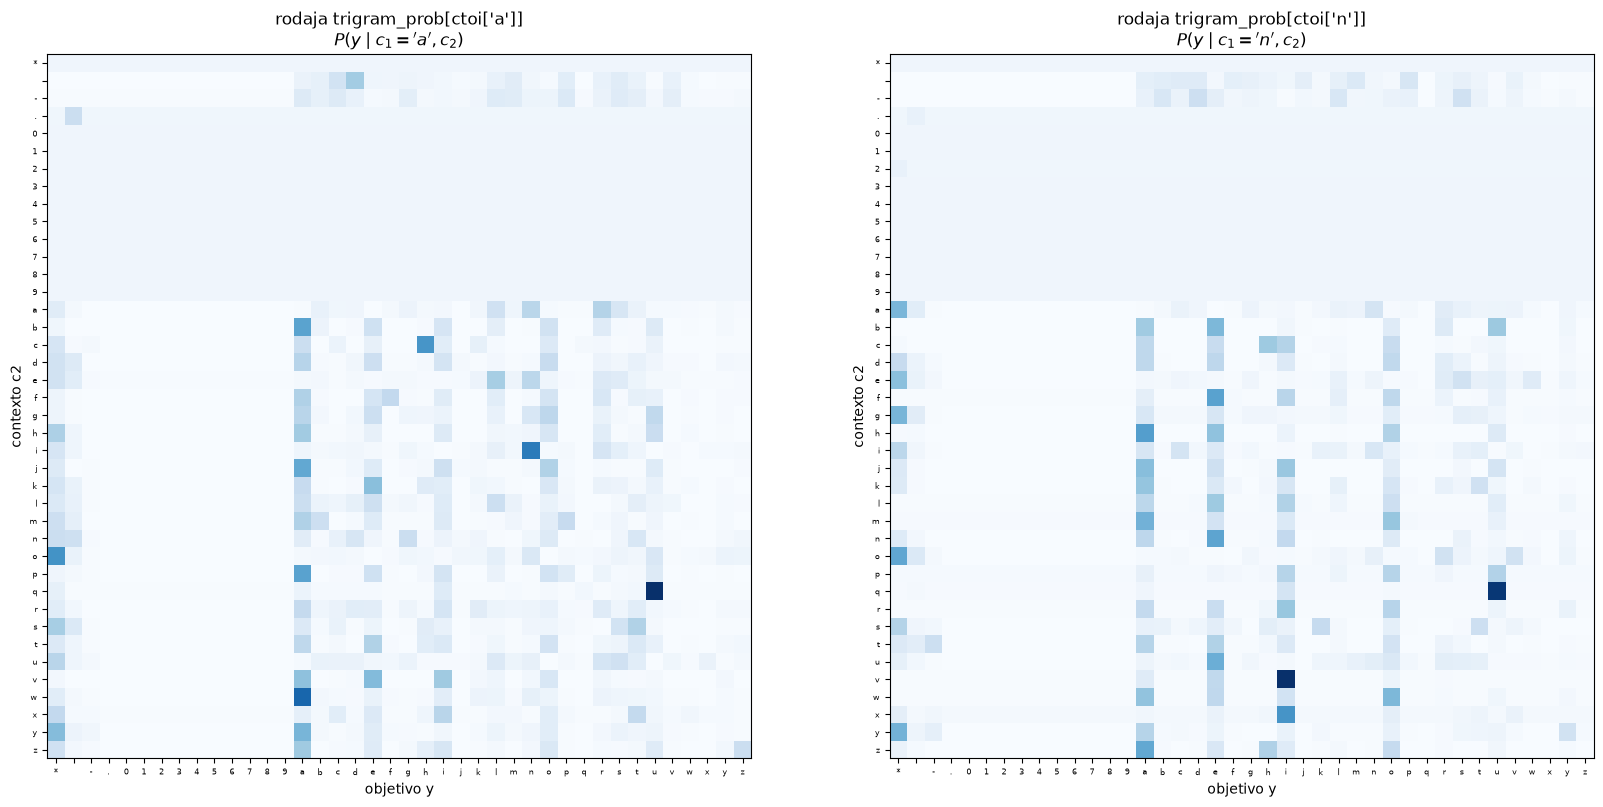

diferencia media entre las dos rodajas: 0.0134
Las dos tablas NO son iguales: el primer caracter del contexto cambia la prediccion.
El tensor guarda 40 tablas como estas, una por cada c1 posible.


In [18]:
# Mapa de calor: comparamos dos "rodajas" distintas del tensor.
# Cada rodaja trigram_prob[i] es una matriz (c2, objetivo): la tabla de predicciones
# condicionada a que el primer caracter del contexto fue itoc[i].
# Si las 40 rodajas fueran iguales, el caracter extra no aportaria nada.
c1_a, c1_b = 'a', 'n'

fig, axes = plt.subplots(1, 2, figsize=(17, 8))

for ax, c1 in zip(axes, [c1_a, c1_b]):
    i = ctoi[c1]
    ax.imshow(trigram_prob[i], cmap='Blues')
    ax.set_title(f"rodaja trigram_prob[ctoi['{c1}']]\n$P(y \\mid c_1='{c1}', c_2)$")
    ax.set_xlabel('objetivo y'); ax.set_ylabel('contexto c2')
    # Ponemos los caracteres del vocabulario como etiquetas de los ejes
    ax.set_xticks(range(nclasses)); ax.set_xticklabels(charset, fontsize=6)
    ax.set_yticks(range(nclasses)); ax.set_yticklabels(charset, fontsize=6)

plt.tight_layout()
plt.show()

# Cuantificamos cuanto difieren: si fueran identicas, la diferencia media seria 0.
dif = np.abs(trigram_prob[ctoi[c1_a]] - trigram_prob[ctoi[c1_b]]).mean()
print(f"diferencia media entre las dos rodajas: {dif:.4f}")
print('Las dos tablas NO son iguales: el primer caracter del contexto cambia la prediccion.')
print('El tensor guarda 40 tablas como estas, una por cada c1 posible.')

### 6.7 La NLL del trigrama estadístico

El notebook original calculaba la NLL con un bucle que recorría palabra por palabra. Acá hacemos lo mismo en una línea:

```python
-np.log(P[xs1, xs2, ys]).mean()
```

**Cómo funciona `P[xs1, xs2, ys]`:** los tres son arrays de la misma longitud `n`. NumPy los empareja posición a posición y devuelve un array de `n` valores donde el elemento `k` es `P[xs1[k], xs2[k], ys[k]]`. Es decir: **la probabilidad que el modelo le asignó al caracter que realmente ocurrió**, para cada uno de los `n` ejemplos.

Después: `np.log(...)` saca el logaritmo de cada una, `.mean()` las promedia y el `-` cambia el signo. Eso es exactamente la fórmula de la NLL.

**Qué esperamos:** que la NLL sea bastante menor que 3.6889 (el uniforme). Y además medimos la referencia marginal de un solo caracter, para saber **cuánto aporta** el segundo caracter de contexto.

In [19]:
def nll_trigrama(P, xs1, xs2, ys):
    """NLL promedio por caracter del modelo de trigramas.

    P   : tensor (40, 40, 40) normalizado sobre el eje 2
    xs1 : indices del primer caracter de contexto   (n,)
    xs2 : indices del segundo caracter de contexto  (n,)
    ys  : indices del caracter objetivo             (n,)
    """
    # Indexacion con tres arrays a la vez: toma P[xs1[k], xs2[k], ys[k]] para cada k.
    probs = P[xs1.numpy(), xs2.numpy(), ys.numpy()]
    # -mean(log(p)) -> la formula de la NLL
    return -np.log(probs).mean()


def nll_marginal(P, xs2, ys):
    """Lo mismo para la referencia de UN caracter de contexto (matriz 40x40)."""
    return -np.log(P[xs2.numpy(), ys.numpy()]).mean()


# Medimos el modelo en los DOS conjuntos.
tri_stat_train = nll_trigrama(trigram_prob, x1_tr, x2_tr, y_tr)
tri_stat_test  = nll_trigrama(trigram_prob, x1_te, x2_te, y_te)

# Y la referencia de un solo caracter, derivada del mismo tensor.
marg_train = nll_marginal(marginal_prob, x2_tr, y_tr)
marg_test  = nll_marginal(marginal_prob, x2_te, y_te)

print('=== MODELO 1: TRIGRAMA ESTADISTICO (alpha=1) ===')
print(f'NLL train : {tri_stat_train:.4f}')
print(f'NLL test  : {tri_stat_test:.4f}')
print(f'perplejidad en test: {np.exp(tri_stat_test):.1f} caracteres')
print()
print('--- cuanto aporta el SEGUNDO caracter de contexto? ---')
print(f'1 caracter de contexto (marginal) test: {marg_test:.4f}')
print(f'2 caracteres de contexto (trigrama) test: {tri_stat_test:.4f}')
print(f'mejora: {marg_test - tri_stat_test:+.4f} nats '
      f'({100 * (marg_test - tri_stat_test) / marg_test:.1f}%)')
print()
print(f'modelo uniforme (referencia)    : {nll_uniforme:.4f}')
print(f'mejora del trigrama sobre el uniforme: {nll_uniforme - tri_stat_test:+.4f} nats')
print()
# La brecha train/test mide el sobreajuste: cuanto peor le va con datos que no vio.
print('--- brecha train/test (indicador de sobreajuste) ---')
print(f'1 caracter: {marg_test - marg_train:+.4f}')
print(f'trigrama  : {tri_stat_test - tri_stat_train:+.4f}  <- mas grande: mas parametros, mas memorizacion')

=== MODELO 1: TRIGRAMA ESTADISTICO (alpha=1) ===
NLL train : 2.4325
NLL test  : 2.4419
perplejidad en test: 11.5 caracteres

--- cuanto aporta el SEGUNDO caracter de contexto? ---
1 caracter de contexto (marginal) test: 2.6589
2 caracteres de contexto (trigrama) test: 2.4419
mejora: +0.2170 nats (8.2%)

modelo uniforme (referencia)    : 3.6889
mejora del trigrama sobre el uniforme: +1.2470 nats

--- brecha train/test (indicador de sobreajuste) ---
1 caracter: -0.0050
trigrama  : +0.0094  <- mas grande: mas parametros, mas memorizacion


### 6.8 El efecto de $\alpha$: regularización en acción

El valor $\alpha = 1$ es la elección clásica de Laplace, pero no es necesariamente la mejor. Con 64.000 celdas y solo ~940.000 observaciones, sumar 1 a todo agrega 64.000 "observaciones imaginarias": es mucho suavizado para los contextos raros.

Barramos $\alpha$ y observemos el comportamiento típico de un hiperparámetro de regularización:

- $\alpha$ **chico** → el modelo confía más en los conteos. La NLL de **train** baja (se ajusta mejor a lo visto), pero la de **test** puede empeorar si confía demasiado en conteos de 1 o 2 observaciones.
- $\alpha$ **grande** → el modelo es más conservador. La NLL de **train** sube, pero la de **test** puede mejorar.

El mínimo de la curva de **test** marca el equilibrio entre *ajustar* y *generalizar*. Ese es el **bias-variance trade-off**.

> ⚠️ **Honestidad metodológica:** elegir $\alpha$ mirando el conjunto de **test** es, estrictamente, hacer trampa (estaríamos usando el test para tomar una decisión de entrenamiento; para eso correspondería un tercer conjunto, de *validación*). Acá lo hacemos **solo para visualizar el fenómeno**, y para la comparación final nos quedamos con $\alpha = 1$, fijado de antemano.

In [20]:
# Barrido de alpha. Reutilizamos trigram_count (los conteos crudos) y solo cambiamos el suavizado.
alphas = [10.0, 3.0, 1.0, 0.3, 0.1, 0.03, 0.01, 0.003]
hist_alpha = []

print(f"{'alpha':>7} | {'NLL train':>10} | {'NLL test':>10} | brecha")
print('-' * 48)
for a in alphas:
    P = trigram_count + a                              # suavizado
    P = P / P.sum(axis=2, keepdims=True)               # normalizacion
    tr = nll_trigrama(P, x1_tr, x2_tr, y_tr)
    te = nll_trigrama(P, x1_te, x2_te, y_te)
    hist_alpha.append((a, tr, te))
    print(f'{a:>7} | {tr:>10.4f} | {te:>10.4f} | {te - tr:+.4f}')

# Buscamos el alpha con la menor NLL de test (solo para ilustrar donde esta el optimo).
# min(..., key=...) devuelve el elemento que minimiza la funcion key; t[2] es la NLL de test.
mejor_alpha = min(hist_alpha, key=lambda t: t[2])
print()
print(f'menor NLL de test con alpha={mejor_alpha[0]}: {mejor_alpha[2]:.4f}')
print(f'(con alpha=1, el que usamos para comparar: {tri_stat_test:.4f})')

  alpha |  NLL train |   NLL test | brecha
------------------------------------------------
   10.0 |     2.5183 |     2.5222 | +0.0038
    3.0 |     2.4561 |     2.4630 | +0.0069
    1.0 |     2.4325 |     2.4419 | +0.0094
    0.3 |     2.4224 |     2.4342 | +0.0118
    0.1 |     2.4190 |     2.4329 | +0.0139
   0.03 |     2.4177 |     2.4337 | +0.0160
   0.01 |     2.4172 |     2.4352 | +0.0179


  0.003 |     2.4171 |     2.4371 | +0.0200

menor NLL de test con alpha=0.1: 2.4329
(con alpha=1, el que usamos para comparar: 2.4419)


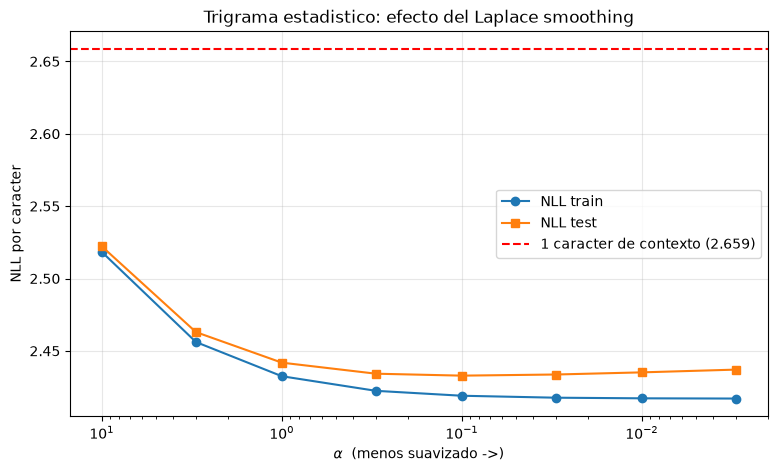

Al reducir alpha, train baja SIEMPRE (el modelo se pega a los datos vistos)
pero test toca un minimo y despues empeora: ese es el sobreajuste apareciendo.


In [21]:
# Graficamos las dos curvas para ver el trade-off.
# Eje x en escala logaritmica porque los alphas varian en ordenes de magnitud.
a_vals  = [h[0] for h in hist_alpha]
tr_vals = [h[1] for h in hist_alpha]
te_vals = [h[2] for h in hist_alpha]

plt.figure(figsize=(9, 5))
plt.semilogx(a_vals, tr_vals, 'o-', label='NLL train')
plt.semilogx(a_vals, te_vals, 's-', label='NLL test')
# axhline dibuja una linea horizontal: la referencia de 1 solo caracter de contexto
plt.axhline(marg_test, color='red', linestyle='--',
            label=f'1 caracter de contexto ({marg_test:.3f})')
plt.gca().invert_xaxis()       # alpha decreciente de izquierda a derecha = "menos regularizacion"
plt.xlabel(r'$\alpha$  (menos suavizado ->)')
plt.ylabel('NLL por caracter')
plt.title('Trigrama estadistico: efecto del Laplace smoothing')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

print('Al reducir alpha, train baja SIEMPRE (el modelo se pega a los datos vistos)')
print('pero test toca un minimo y despues empeora: ese es el sobreajuste apareciendo.')

### 6.9 Generando nombres con el trigrama estadístico

Generación **autorregresiva**: generamos de a un caracter, y cada caracter nuevo pasa a formar parte del contexto del siguiente. El procedimiento es el mismo del notebook original, con un cambio importante: hay que **desplazar una ventana de dos caracteres**.

1. Arrancar con el contexto `(c1, c2) = ('*', '*')`.
2. Tomar la distribución `trigram_prob[ctoi[c1], ctoi[c2]]` (los 40 valores de probabilidad).
3. Sortear un caracter según esa distribución (`np.random.choice` con `p=`).
4. Si salió `'*'`, la palabra terminó.
5. Si no, **desplazar la ventana**: el nuevo contexto es `(c2, caracter_nuevo)` — descartamos el más viejo.
6. Repetir.

Agregamos un `max_len` como corte de seguridad: si el modelo entra en un bucle (por ejemplo generando `'aaaaa...'`), paramos igual. Sin ese límite, el `while` podría no terminar nunca.

In [22]:
def generar_trigrama_estadistico(P, max_len=40, rng=None):
    """Genera un nombre con el modelo estadistico de trigramas (autoregresivo).

    P       : tensor (40, 40, 40) de probabilidades
    max_len : corte de seguridad para no generar nombres infinitos
    rng     : generador aleatorio de numpy (para reproducibilidad)
    """
    if rng is None:
        rng = np.random

    out = []
    c1, c2 = '*', '*'                    # arrancamos con los DOS marcadores de inicio

    for _ in range(max_len):             # for en lugar de while: el limite queda garantizado
        # Distribucion del siguiente caracter dado el contexto actual: un vector de 40 probabilidades
        p = P[ctoi[c1], ctoi[c2]]
        # Sorteamos un caracter RESPETANDO esa distribucion (los mas probables salen mas seguido)
        nuevo = rng.choice(charset, p=p)

        if nuevo == '*':                 # el modelo decidio terminar la palabra
            break

        out.append(nuevo)
        c1, c2 = c2, nuevo               # DESPLAZAMOS la ventana: el mas viejo (c1) se descarta

    return ''.join(out)


# Semilla propia para que la generacion sea reproducible
rng_gen = np.random.RandomState(0)

print('=== 10 nombres del MODELO 1 (trigrama estadistico) ===')
nombres_stat = [generar_trigrama_estadistico(trigram_prob, rng=rng_gen) for _ in range(10)]
for n in nombres_stat:
    print(' ', n)

=== 10 nombres del MODELO 1 (trigrama estadistico) ===
  mookendruishita
  assovoaqan vilio k5kkhumanj
  poia deava claihach
  cer
  savey-sai fain
  plak
  mullana
  nas
  perverne
  wessbunterosauren


---

# Parte II: el trigrama **neuronal**

Hasta acá "entrenamos" contando. Ahora vamos a hacer que una red neuronal **aprenda** las probabilidades del trigrama por su cuenta, con descenso por gradiente. El objetivo es el mismo (minimizar la NLL), pero el camino es completamente distinto.

## 7. One-Hot Encoding y la concatenación de dos One-Hot

### 7.1 Repaso: ¿por qué One-Hot?

Una red neuronal solo sabe multiplicar y sumar números. No entiende de letras. ¿Cómo le pasamos un caracter?

**One-Hot Encoding:** representamos cada caracter con un vector de 40 posiciones, todo **ceros** excepto un único **1** en la posición del caracter.

$$\text{'a'} \;(\text{índice } 14) \;\longrightarrow\; [0, 0, \dots, \underbrace{1}_{\text{pos }14}, \dots, 0] \in \mathbb{R}^{40}$$

**¿Por qué no pasar directamente el índice `14`?** Porque la red interpretaría ese número como una **cantidad** con orden y magnitud: entendería que `'z'` (39) es "casi tres veces" `'a'` (14), y que `'m'` está "en el medio" de las dos. Los caracteres no tienen ese orden. El One-Hot los trata como **categorías independientes**, sin relación de magnitud entre ellas.

### 7.2 El truco fundamental del One-Hot

Si $X$ es un vector one-hot con el 1 en la posición $k$, entonces:

$$X \cdot W = \text{fila } k \text{ de } W$$

Los demás pesos se multiplican por 0 y desaparecen. **Multiplicar por un one-hot es ir a buscar una fila de la matriz de pesos.** Esto es clave para entender qué está aprendiendo el modelo: la fila $k$ de $W$ *es* la predicción asociada al caracter $k$.

### 7.3 Lo nuevo: **concatenar** dos One-Hot

Para el trigrama tenemos **dos** caracteres de contexto. La solución más directa es codificar cada uno por separado y **pegar** los dos vectores:

$$X = [\underbrace{\text{onehot}(c_1)}_{40} \;\|\; \underbrace{\text{onehot}(c_2)}_{40}] \in \mathbb{R}^{80}$$

El resultado es un vector de **80 posiciones con exactamente dos 1**: uno en la primera mitad (que indica cuál es $c_1$) y otro en la segunda mitad (que indica cuál es $c_2$).

| Operación | Entrada | Salida |
|---|---|---|
| `F.one_hot(xs1, num_classes=40)` | `(n,)` | `(n, 40)` |
| `F.one_hot(xs2, num_classes=40)` | `(n,)` | `(n, 40)` |
| `torch.cat([a, b], dim=1)` | dos de `(n, 40)` | `(n, 80)` |

**`dim=1` es crítico.** Es el eje de las columnas (las *características*). Concatenar en `dim=1` pega los vectores **a lo ancho**: cada fila sigue siendo un ejemplo, ahora con 80 características. Si usáramos `dim=0` pegaríamos a lo **largo**, obteniendo `(2n, 40)`: el doble de ejemplos de 40 características, que es algo completamente distinto y sin sentido acá.

In [23]:
# Veamos el One-Hot y la concatenacion sobre un unico ejemplo concreto.
i = 2                                     # tercer ejemplo de train
a = x1_tr[i:i+1]                          # usamos slicing i:i+1 para CONSERVAR la dimension de "lote"
b = x2_tr[i:i+1]                          # (si usaramos x1_tr[i] obtendriamos un escalar, sin forma (1,))
y = y_tr[i:i+1]

print(f"contexto: ('{itoc[a.item()]}', '{itoc[b.item()]}')  ->  objetivo: '{itoc[y.item()]}'")
print(f'indices : ({a.item()}, {b.item()}) -> {y.item()}')
print()

# F.one_hot(tensor_de_indices, num_classes=N):
#   convierte cada indice en un vector de N ceros con un 1 en la posicion del indice.
#   Devuelve int64; .float() lo pasa a float32, que es lo que necesitan las redes para operar.
enc_a = F.one_hot(a, num_classes=nclasses).float()    # (1, 40)
enc_b = F.one_hot(b, num_classes=nclasses).float()    # (1, 40)

# torch.cat([t1, t2], dim=1): pega los tensores a lo ANCHO (por columnas).
xenc = torch.cat([enc_a, enc_b], dim=1)               # (1, 80)

print('one_hot(c1) :', tuple(enc_a.shape))
print('one_hot(c2) :', tuple(enc_b.shape))
print('concatenado :', tuple(xenc.shape), ' <- 40 + 40 = 80 entradas')
print()
# .nonzero() devuelve las posiciones de los valores distintos de cero.
# [:, 1] toma la columna de los indices (la columna 0 seria el numero de fila).
print('donde estan los unos?:', xenc.nonzero()[:, 1].tolist())
print(f'  el primer 1 esta en la posicion {a.item()}      -> codifica c1 = {itoc[a.item()]!r}')
print(f'  el segundo 1 esta en la posicion {40 + b.item()} = 40 + {b.item()} -> codifica c2 = {itoc[b.item()]!r}')
print()
print('suma del vector:', xenc.sum().item(), '(exactamente dos unos, el resto ceros)')

contexto: ('k', 'o')  ->  objetivo: 't'
indices : (24, 28) -> 33

one_hot(c1) : (1, 40)
one_hot(c2) : (1, 40)
concatenado : (1, 80)  <- 40 + 40 = 80 entradas

donde estan los unos?: [24, 68]
  el primer 1 esta en la posicion 24      -> codifica c1 = 'k'
  el segundo 1 esta en la posicion 68 = 40 + 28 -> codifica c2 = 'o'

suma del vector: 2.0 (exactamente dos unos, el resto ceros)


forma del lote completo de "bojia": (6, 80) -> (6 ejemplos, 80 entradas)


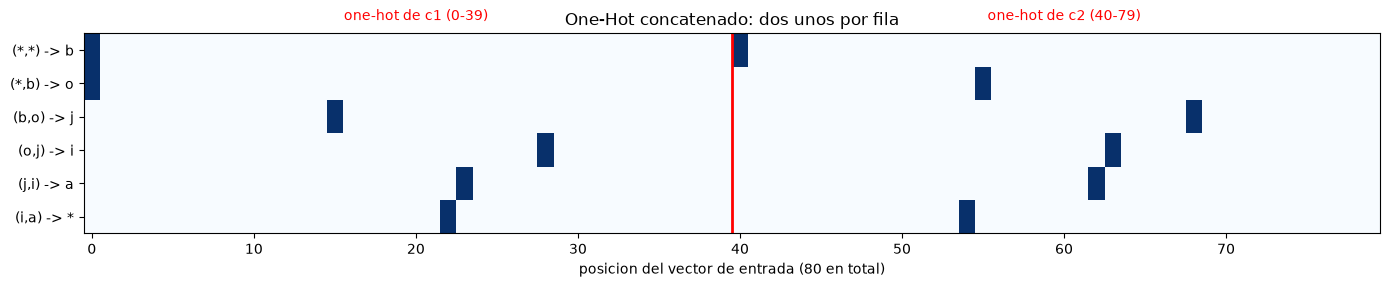

In [24]:
# Visualizamos el One-Hot concatenado de los 6 ejemplos de 'bojia'.
# Cada FILA es un ejemplo; las primeras 40 columnas codifican c1 y las ultimas 40 codifican c2.
x1_demo, x2_demo, y_demo = build_trigramas([dataset[3]])    # 'bojia' -> 6 ejemplos

enc_demo = torch.cat([F.one_hot(x1_demo, num_classes=nclasses).float(),
                      F.one_hot(x2_demo, num_classes=nclasses).float()], dim=1)

print('forma del lote completo de "bojia":', tuple(enc_demo.shape), '-> (6 ejemplos, 80 entradas)')

plt.figure(figsize=(14, 3))
plt.imshow(enc_demo, cmap='Blues', aspect='auto')
# axvline: linea vertical en la frontera entre las dos mitades del vector
plt.axvline(nclasses - 0.5, color='red', linewidth=2)
plt.text(20, -0.9, 'one-hot de c1 (0-39)', ha='center', color='red')
plt.text(60, -0.9, 'one-hot de c2 (40-79)', ha='center', color='red')
plt.yticks(range(len(y_demo)),
           [f"({itoc[x1_demo[k].item()]},{itoc[x2_demo[k].item()]}) -> {itoc[y_demo[k].item()]}"
            for k in range(len(y_demo))])
plt.xlabel('posicion del vector de entrada (80 en total)')
plt.title('One-Hot concatenado: dos unos por fila')
plt.tight_layout()
plt.show()

## 8. Logits, Softmax y Cross-Entropy

### 8.1 ¿Qué sale de la red? Los **logits**

La red hace `logits = X @ W` y devuelve 40 números por ejemplo. Esos números **no son probabilidades**: pueden ser negativos y no suman 1. Los interpretamos como **log-conteos**, igual que en el notebook original:

$$\text{logits} = \log(\text{counts}) \qquad \Longrightarrow \qquad \text{counts} = e^{\text{logits}}$$

Exponenciar los vuelve positivos (que es lo que un conteo debe ser), y normalizar los convierte en probabilidades. Esos dos pasos juntos son la función **softmax**.

### 8.2 Softmax

$$\text{softmax}(z)_i = \frac{e^{z_i}}{\sum_{j=1}^{40} e^{z_j}}$$

Toma un vector de 40 logits y devuelve 40 números en $[0, 1]$ que suman 1. Propiedades útiles:

- **Monótona:** el logit más grande produce la probabilidad más grande (no cambia el ranking).
- **Invariante a constantes:** sumar la misma constante a todos los logits no cambia el resultado. Esto es lo que permite restar el máximo para ganar estabilidad numérica.

### 8.3 Cross-Entropy = Softmax + NLL

La **cross-entropy** entre la distribución real (un one-hot: probabilidad 1 en el caracter correcto) y la predicha $\hat{p}$ es:

$$H(y, \hat{p}) = -\sum_{i} y_i \log \hat{p}_i = -\log \hat{p}_{y}$$

La suma colapsa en un solo término porque $y$ es one-hot: todos los demás se multiplican por 0. O sea: **la cross-entropy de un ejemplo es exactamente su negative log likelihood.** Son dos nombres para lo mismo cuando la etiqueta es una sola clase correcta.

### 8.4 ¿Por qué usar `F.cross_entropy` en lugar de calcularlo a mano?

Por **estabilidad numérica**. Si un logit es grande, `exp(logit)` desborda a `inf` y todo el cálculo se arruina (`inf/inf = nan`). `F.cross_entropy` usa el truco de restar el máximo:

$$\log \sum_j e^{z_j} = z_{\max} + \log \sum_j e^{z_j - z_{\max}}$$

Matemáticamente idéntico (por la invariancia del softmax), pero ahora el exponente más grande es 0, y $e^0 = 1$ nunca desborda. Además `F.cross_entropy` fusiona softmax y log en una sola operación, lo que da un gradiente más simple y preciso.

**Lo vamos a comprobar:** calculamos la pérdida a mano (paso por paso, como el notebook original) y verificamos que `F.cross_entropy` da **el mismo número**.

In [25]:
# --- CALCULO MANUAL DE SOFTMAX + NLL, paso a paso, sobre los 6 ejemplos de 'bojia' ---
# Usamos una W de 80x40 inicializada al azar (todavia sin entrenar) solo para ver las operaciones.
g = torch.Generator().manual_seed(42)
W_demo = torch.randn((2 * nclasses, nclasses), generator=g)

# PASO 1: forward pass. (6, 80) @ (80, 40) = (6, 40)
logits = enc_demo @ W_demo
print('PASO 1 - logits          :', tuple(logits.shape), '-> 40 numeros por ejemplo')
print('   rango de los logits   : [%.2f, %.2f]  <- NO son probabilidades' % (logits.min(), logits.max()))

# PASO 2: exponenciamos -> "counts" (todos positivos)
counts = logits.exp()
print('PASO 2 - counts = e^logits:', tuple(counts.shape), ' todos positivos:', bool((counts > 0).all()))

# PASO 3: normalizamos por fila -> probabilidades. PASO 2 + PASO 3 = softmax
probs = counts / counts.sum(axis=1, keepdims=True)
print('PASO 3 - probs (softmax) :', tuple(probs.shape), ' cada fila suma:', probs.sum(axis=1)[0].item())

# PASO 4: tomamos la probabilidad de la etiqueta CORRECTA de cada ejemplo.
#   probs[range(n), ys] empareja fila k con columna ys[k] -> n valores.
n_demo = len(y_demo)
p_correctas = probs[range(n_demo), y_demo]
print('PASO 4 - p de la etiqueta correcta:', [round(p, 4) for p in p_correctas.tolist()])

# PASO 5: -log y promedio -> NLL
loss_manual = -p_correctas.log().mean()
print('PASO 5 - NLL manual      : %.6f' % loss_manual.item())

PASO 1 - logits          : (6, 40) -> 40 numeros por ejemplo
   rango de los logits   : [-4.04, 4.32]  <- NO son probabilidades
PASO 2 - counts = e^logits: (6, 40)  todos positivos: True
PASO 3 - probs (softmax) : (6, 40)  cada fila suma: 0.9999998807907104
PASO 4 - p de la etiqueta correcta: [0.059, 0.0293, 0.0096, 0.1193, 0.0162, 0.0551]
PASO 5 - NLL manual      : 3.359857


In [26]:
# --- COMPROBACION: F.cross_entropy da EXACTAMENTE lo mismo ---
# F.cross_entropy(logits, targets) hace internamente softmax + log + NLL + promedio.
# OJO: recibe los LOGITS crudos, no las probabilidades (el softmax lo aplica ella).
loss_ce = F.cross_entropy(logits, y_demo)

print('NLL calculada a mano  : %.10f' % loss_manual.item())
print('F.cross_entropy       : %.10f' % loss_ce.item())
print('diferencia absoluta   : %.2e' % abs(loss_manual.item() - loss_ce.item()))
print()
# torch.allclose(a, b): True si son iguales dentro de la tolerancia de punto flotante
assert torch.allclose(loss_manual, loss_ce), 'deben coincidir: son la misma formula'
print('OK: softmax + NLL  ==  cross_entropy')
print()

# --- POR QUE IMPORTA LA ESTABILIDAD NUMERICA ---
# Repetimos el calculo con logits ARTIFICIALMENTE grandes (como podrian aparecer
# a mitad de un entrenamiento con un learning rate demasiado alto).
logits_grandes = logits * 100

counts_g = logits_grandes.exp()                                  # e^900 = inf
probs_g = counts_g / counts_g.sum(axis=1, keepdims=True)         # inf/inf = nan
loss_g_manual = -probs_g[range(n_demo), y_demo].log().mean()
loss_g_ce = F.cross_entropy(logits_grandes, y_demo)

print('con logits x100 (max = %.0f):' % logits_grandes.max().item())
print('  calculo manual   :', loss_g_manual.item(), '<- se rompe: exp() desborda a inf')
print('  F.cross_entropy  : %.4f' % loss_g_ce.item(), '  <- sigue funcionando')
print()
print('Por eso para entrenar usamos F.cross_entropy, aunque la formula sea la misma.')

NLL calculada a mano  : 3.3598573208
F.cross_entropy       : 3.3598575592
diferencia absoluta   : 2.38e-07

OK: softmax + NLL  ==  cross_entropy

con logits x100 (max = 432):
  calculo manual   : nan <- se rompe: exp() desborda a inf
  F.cross_entropy  : 190.0367   <- sigue funcionando

Por eso para entrenar usamos F.cross_entropy, aunque la formula sea la misma.


## 9. El entrenamiento: descenso por gradiente

### 9.1 Los 9 pasos

Son los mismos del notebook original:

1. **Inicialización aleatoria** de `W` con `torch.randn` y `requires_grad=True`.
2. **Forward pass:** one-hot concatenado de la entrada.
3. **Logits:** `logits = xenc @ W`.
4. **Softmax** (dentro de `cross_entropy`).
5. **NLL** (la pérdida).
6. **Limpiar gradientes:** `W.grad = None`.
7. **Backpropagation:** `loss.backward()`.
8. **Actualizar:** `W.data += -lr * W.grad`.
9. **Repetir.**

**¿Qué hace `requires_grad=True`?** Le dice a PyTorch: "este tensor es un parámetro que quiero ajustar". A partir de ahí, PyTorch construye un **grafo de cómputo** que registra cada operación hecha con `W`. Cuando llamamos `loss.backward()`, recorre ese grafo **hacia atrás** aplicando la regla de la cadena, y deposita en `W.grad` la derivada $\partial \text{loss} / \partial W$. Eso es la **backpropagation**.

**¿Por qué limpiar los gradientes?** Porque `backward()` **acumula** (suma) en `.grad` en lugar de sobrescribir. Si no lo limpiáramos, en la iteración 10 tendríamos la suma de los 10 gradientes anteriores y el paso sería enorme y sin sentido. Es uno de los bugs más comunes al escribir un entrenamiento a mano.

**¿Cómo actúa el gradiente sobre los pesos?** `W.grad` tiene **exactamente la misma forma** que `W`: `(80, 40)`. Cada elemento `W.grad[i, j]` dice: *"si aumentás `W[i, j]` un poquito, la pérdida cambia en esta proporción"*. Como queremos **bajar** la pérdida, nos movemos en la dirección **opuesta**: `W.data += -lr * W.grad`. Ese es el **descenso por gradiente**.

Con one-hot hay una propiedad muy elegante: como la entrada es cero en todas las posiciones menos dos, **solo se actualizan las filas de `W` correspondientes a los caracteres presentes en el mini-lote**. Las demás filas quedan intactas en ese paso.

### 9.2 El learning rate (`lr`)

Es el tamaño del paso:

- **Muy chico** → el entrenamiento es lentísimo, nunca llega.
- **Muy grande** → los pasos se pasan del mínimo, la pérdida oscila o **explota**.
- **Justo** → baja rápido y se estabiliza.

Usamos `lr = 50`, igual que el notebook original. Parece enorme, pero tiene una razón: con la entrada one-hot cada fila de `W` solo recibe gradiente de los ejemplos que contienen ese caracter, así que los gradientes son **muy chicos** y hacen falta pasos grandes. Además agregamos una **bajada de learning rate** (`lr/10`) en el último tramo: pasos grandes al principio para avanzar rápido, pasos chicos al final para afinar sin oscilar.

### 9.3 Entrenamiento por mini-lotes (*mini-batch*)

El notebook original hacía el *forward pass* con **todo** el dataset a la vez. Acá no podemos: el one-hot de las ~940.000 tripletas con 80 columnas ocuparía `940.000 × 80 × 4 bytes ≈ 300 MB`, y los tensores intermedios del *backward* lo multiplican varias veces.

La solución estándar es el **descenso por gradiente estocástico por mini-lotes**: en cada iteración tomamos una muestra al azar de `batch_size` ejemplos y calculamos el gradiente **solo sobre ellos**.

- El gradiente del mini-lote es una **estimación ruidosa** del gradiente real.
- Es ruidosa, pero **no sesgada**: en promedio apunta en la dirección correcta.
- A cambio, podemos hacer **miles** de pasos en el tiempo que llevaría hacer unas pocas decenas con el dataset completo. En la práctica se converge mucho más rápido.

Importante: la **evaluación** sí la hacemos sobre el conjunto completo (train y test), recorriéndolo en bloques para no quedarnos sin memoria. Las NLL que reportamos no son estimaciones de mini-lote: son exactas.

In [27]:
def encode_trigrama(a, b):
    """One-Hot concatenado del trigrama: dos tensores (n,) -> un tensor (n, 80)."""
    return torch.cat([F.one_hot(a, num_classes=nclasses).float(),
                      F.one_hot(b, num_classes=nclasses).float()], dim=1)


def evaluar_nll(forward, a_full, b_full, ys, chunk=200_000):
    """NLL exacta de un modelo neuronal sobre un conjunto completo, procesado en bloques.

    forward : funcion (idx_c1, idx_c2) -> logits
    a_full  : tensor de indices de c1 del conjunto completo
    b_full  : tensor de indices de c2 del conjunto completo
    ys      : tensor de objetivos
    chunk   : cuantos ejemplos procesar por bloque (para no agotar la memoria)
    """
    total = 0.0
    # torch.no_grad(): desactiva el autograd. No necesitamos gradientes para evaluar,
    # y asi PyTorch no guarda el grafo de computo -> mucha menos memoria y mas velocidad.
    with torch.no_grad():
        for i in range(0, len(ys), chunk):
            logits = forward(a_full[i:i + chunk], b_full[i:i + chunk])
            # reduction='sum' suma en lugar de promediar, para poder acumular entre bloques
            # y dividir UNA sola vez al final por el total exacto de ejemplos.
            total += F.cross_entropy(logits, ys[i:i + chunk], reduction='sum').item()
    return total / len(ys)

In [28]:
def entrenar(params, forward, a_full, b_full, ys, lr, iteraciones, batch_size,
             decaer_en=None, seed=7, cada=None):
    """Bucle de entrenamiento explicito por descenso por gradiente con mini-lotes.

    params      : lista de tensores con requires_grad=True (los parametros a aprender)
    forward     : funcion que recibe los indices del lote y devuelve los logits
    a_full      : tensor completo de indices de c1 (de aca sacamos los lotes)
    b_full      : tensor completo de indices de c2
    ys          : tensor completo de objetivos
    lr          : learning rate (tamano del paso)
    iteraciones : cuantos pasos de descenso por gradiente dar
    batch_size  : cuantos ejemplos por mini-lote
    decaer_en   : iteracion a partir de la cual usar lr/10 (None = sin decaimiento)
    cada        : cada cuantas iteraciones imprimir el progreso
    """
    g = torch.Generator().manual_seed(seed)   # generador propio -> muestreo reproducible
    n = len(ys)
    historial = []                            # guardamos la perdida de cada iteracion
    lr_actual = lr
    if cada is None:
        cada = max(1, iteraciones // 10)

    t0 = time.time()
    for k in range(iteraciones):
        # Bajada del learning rate en el ultimo tramo
        if decaer_en is not None and k == decaer_en:
            lr_actual = lr / 10

        # --- 1) armamos el MINI-LOTE: batch_size indices al azar entre 0 y n-1 ---
        idx = torch.randint(0, n, (batch_size,), generator=g)

        # --- 2) FORWARD PASS: one-hot concatenado -> logits ---
        logits = forward(a_full[idx], b_full[idx])          # (batch_size, 40)

        # --- 3) LOSS: softmax + NLL, en una sola operacion numericamente estable ---
        loss = F.cross_entropy(logits, ys[idx])

        # --- 4) LIMPIAMOS los gradientes (backward ACUMULA, no sobrescribe) ---
        for p in params:
            p.grad = None

        # --- 5) BACKWARD PASS: autograd calcula dloss/dp para cada parametro ---
        loss.backward()

        # --- 6) UPDATE: paso de descenso por gradiente, en direccion OPUESTA al gradiente ---
        for p in params:
            # .data accede al tensor crudo, SIN que la operacion entre al grafo de autograd
            # (no queremos derivar la actualizacion de los pesos en si misma).
            p.data += -lr_actual * p.grad

        historial.append(loss.item())

        if k % cada == 0 or k == iteraciones - 1:
            print(f'  iter {k:>6}/{iteraciones}   loss(lote) = {loss.item():.4f}   lr = {lr_actual}')

    print(f'  entrenado en {time.time() - t0:.1f}s')
    return historial

## 10. Modelo 2: trigrama neuronal **lineal** (`80 -> 40`)

Esta es la arquitectura directamente comparable con la del notebook original, que tenía 40 entradas y una `W` de `(40, 40)`.

- **Entrada:** dos one-hot concatenados → 80 posiciones.
- **Pesos:** `W` de forma `(80, 40)` → 40 neuronas con 80 entradas cada una. **3.200 parámetros.**
- **Salida:** 40 logits → softmax → probabilidades.
- **Pérdida:** NLL (vía `cross_entropy`).

### 10.1 ¿Qué es una capa de 40 neuronas?

Una **neurona** recibe entradas, las multiplica por sus pesos y las suma: $z = \sum_i w_i x_i$. Una **capa** es un conjunto de neuronas que mira la misma entrada.

La matriz `W` de `(80, 40)` **es** la capa: **cada columna de `W` son los pesos de una neurona**, y la neurona $j$ produce el logit del caracter $j$. El producto `xenc @ W` calcula las 40 neuronas de todos los ejemplos del lote de una sola vez. Eso es todo lo que hace una capa lineal: una multiplicación de matrices.

Necesitamos 40 neuronas (y no una) porque la salida tiene que ser una **probabilidad por cada caracter posible**: 40 números. Una sola neurona daría un único número, y su softmax sería trivialmente 1.

### 10.2 ¿Por qué funciona esta arquitectura?

Partamos la matriz `W` de `(80, 40)` en sus dos mitades: $W = \begin{bmatrix} U \\ V \end{bmatrix}$, con $U$ de `(40, 40)` (las filas 0-39) y $V$ de `(40, 40)` (las filas 40-79).

Como la entrada es un one-hot concatenado con un 1 en la posición $c_1$ y otro en la posición $40 + c_2$, el producto **selecciona y suma** dos filas:

$$\text{logits} = X \cdot W = \underbrace{U_{c_1}}_{\text{fila } c_1 \text{ de } U} + \underbrace{V_{c_2}}_{\text{fila } c_2 \text{ de } V}$$

Funciona porque el modelo **sí usa los dos caracteres**: cada uno aporta su propio vector de 40 logits y el resultado es la suma. El caracter $c_1$ puede subir o bajar la puntuación de ciertos objetivos, independientemente de lo que haga $c_2$.

Y es una mejora real sobre el modelo de un solo caracter: ese modelo **solo** tendría el término $V_{c_2}$; acá agregamos el término $U_{c_1}$.

### 10.3 Y acá está su **limitación fundamental**

Aplicando softmax a esa suma:

$$P(y \mid c_1, c_2) = \frac{e^{U_{c_1,y} + V_{c_2,y}}}{\sum_{y'} e^{U_{c_1,y'} + V_{c_2,y'}}} \;\propto\; \underbrace{e^{U_{c_1,y}}}_{\text{factor de } c_1} \cdot \underbrace{e^{V_{c_2,y}}}_{\text{factor de } c_2}$$

El modelo es **aditivo en los logits**, lo que equivale a ser **multiplicativo en las probabilidades**: la contribución de cada caracter de contexto es un factor independiente. Le falta cualquier término de **interacción** $I_{c_1, c_2, y}$.

**Por qué eso es un problema, con un ejemplo:** supongamos que en el dataset la secuencia `an` es casi siempre seguida de `d` (*santander*, *andes*), pero `en` casi nunca (*enrique*). Para que este modelo capture eso necesitaría que $U_{a,d}$ sea grande (para subir la `d` después de una `a`)... pero ese mismo $U_{a,d}$ **también** sube la `d` en el contexto `(a, x)`, `(a, q)`, `(a, z)` y en los otros 39 contextos que empiezan con `a`. **No puede especializar su respuesta a la combinación particular.**

En otras palabras: el modelo tiene $40 \times 40 \times 2 = 3.200$ parámetros, pero debe describir $40 \times 40 = 1.600$ distribuciones distintas de 40 valores (que serían 64.000 grados de libertad, los mismos del tensor estadístico). Está **estructuralmente restringido**.

> 🔑 **Predicción teórica:** este modelo debería quedar **entre** el modelo de un solo caracter (que ignora $c_1$) y el trigrama estadístico (que modela cada contexto libremente), **sin poder alcanzar a este último**. Lo vamos a verificar numéricamente.

In [29]:
# --- MODELO 2: TRIGRAMA NEURONAL LINEAL (80 entradas -> 40 salidas) ---

# Generador con semilla fija -> los pesos iniciales son siempre los mismos (reproducible).
g = torch.Generator().manual_seed(42)

# W de (80, 40): 40 neuronas (columnas) con 80 entradas cada una (filas).
#   filas 0-39  reciben el one-hot de c1  (la submatriz U)
#   filas 40-79 reciben el one-hot de c2  (la submatriz V)
# torch.randn: inicializacion aleatoria con distribucion normal (media 0, desvio 1).
# requires_grad=True: le pedimos a PyTorch que calcule el gradiente de este tensor.
W = torch.randn((2 * nclasses, nclasses), generator=g, requires_grad=True)

print('--- MODELO 2: TRIGRAMA NEURONAL LINEAL ---')
print('forma de W :', tuple(W.shape))
print('parametros :', W.numel())                 # .numel() = numero total de elementos
print('gradiente antes de backward():', W.grad)  # None: PyTorch lo completa recien al hacer backward
print()

# La funcion forward del modelo: one-hot concatenado y un producto de matrices.
#   (batch, 80) @ (80, 40) = (batch, 40)
# Usamos lambda para tener una funcion corta que capture W.
forward_lineal = lambda a, b: encode_trigrama(a, b) @ W

# Verificamos las formas con un lote chico antes de entrenar.
with torch.no_grad():
    x_t = encode_trigrama(x1_tr[:7], x2_tr[:7])
    o_t = x_t @ W
    print('--- FORMAS EN EL FORWARD PASS (lote de 7 ejemplos) ---')
    print('entrada one-hot concatenada:', tuple(x_t.shape))
    print('logits de salida           :', tuple(o_t.shape), f' rango [{o_t.min():.2f}, {o_t.max():.2f}]')
    print(f'loss inicial               : {F.cross_entropy(o_t, y_tr[:7]).item():.4f}')
    print(f'(referencia del uniforme   : {nll_uniforme:.4f})')

--- MODELO 2: TRIGRAMA NEURONAL LINEAL ---
forma de W : (80, 40)
parametros : 3200
gradiente antes de backward(): None

--- FORMAS EN EL FORWARD PASS (lote de 7 ejemplos) ---
entrada one-hot concatenada: (7, 80)
logits de salida           : (7, 40)  rango [-3.77, 4.34]
loss inicial               : 4.5490
(referencia del uniforme   : 3.6889)


In [30]:
# Entrenamos el modelo. lr=50 igual que el notebook original (gradientes del one-hot chicos),
# con bajada a lr/10 en el ultimo 20% de las iteraciones para afinar sin oscilar.
historial = entrenar(
    params=[W],
    forward=forward_lineal,
    a_full=x1_tr,
    b_full=x2_tr,
    ys=y_tr,
    lr=50,
    iteraciones=5000,
    batch_size=4096,
    decaer_en=4000,
)

  iter      0/5000   loss(lote) = 4.6595   lr = 50


  iter    500/5000   loss(lote) = 2.5821   lr = 50


  iter   1000/5000   loss(lote) = 2.5734   lr = 50


  iter   1500/5000   loss(lote) = 2.5761   lr = 50


  iter   2000/5000   loss(lote) = 2.5928   lr = 50


...

  iter   3000/5000   loss(lote) = 2.5768   lr = 50


  iter   3500/5000   loss(lote) = 2.5619   lr = 50


  iter   4000/5000   loss(lote) = 2.5395   lr = 5.0


  iter   4500/5000   loss(lote) = 2.5216   lr = 5.0


  iter   4999/5000   loss(lote) = 2.5532   lr = 5.0
  entrenado en 11.1s


In [31]:
# Evaluamos en los conjuntos COMPLETOS (no en un mini-lote).
tri_neur_train = evaluar_nll(forward_lineal, x1_tr, x2_tr, y_tr)
tri_neur_test  = evaluar_nll(forward_lineal, x1_te, x2_te, y_te)

print('=== MODELO 2: TRIGRAMA NEURONAL LINEAL (80 -> 40) ===')
print(f'NLL train : {tri_neur_train:.4f}')
print(f'NLL test  : {tri_neur_test:.4f}')
print()
print('--- la escalera completa en test ---')
print(f'1. uniforme                      : {nll_uniforme:.4f}')
print(f'2. 1 caracter de contexto (marg.): {marg_test:.4f}')
print(f'3. trigrama neuronal lineal      : {tri_neur_test:.4f}')
print(f'4. trigrama estadistico          : {tri_stat_test:.4f}  <- el optimo por conteo')
print()
print(f'mejora sobre 1 caracter de contexto: {marg_test - tri_neur_test:+.4f} nats')
print(f'distancia al trigrama estadistico  : {tri_neur_test - tri_stat_test:+.4f} nats')
print()
print('Como predijimos: el modelo lineal aprovecha el segundo caracter y mejora,')
print('pero NO llega al trigrama estadistico. La restriccion aditiva se lo impide.')

=== MODELO 2: TRIGRAMA NEURONAL LINEAL (80 -> 40) ===
NLL train : 2.5628
NLL test  : 2.5605

--- la escalera completa en test ---
1. uniforme                      : 3.6889
2. 1 caracter de contexto (marg.): 2.6589
3. trigrama neuronal lineal      : 2.5605
4. trigrama estadistico          : 2.4419  <- el optimo por conteo

mejora sobre 1 caracter de contexto: +0.0984 nats
distancia al trigrama estadistico  : +0.1186 nats

Como predijimos: el modelo lineal aprovecha el segundo caracter y mejora,
pero NO llega al trigrama estadistico. La restriccion aditiva se lo impide.


In [32]:
# --- COMPROBACION EMPIRICA de que el modelo es ADITIVO ---
# Si logits = U[c1] + V[c2], podemos calcular los logits de dos formas distintas
# y deben coincidir exactamente.
with torch.no_grad():
    i = 5
    a, b = x1_tr[i:i+1], x2_tr[i:i+1]

    # Forma 1: el forward normal, con el one-hot concatenado
    logits_normal = encode_trigrama(a, b) @ W

    # Forma 2: partimos W en sus dos mitades y SUMAMOS las dos filas correspondientes
    U = W[:nclasses]            # filas 0-39   -> la parte que procesa c1
    V = W[nclasses:]            # filas 40-79  -> la parte que procesa c2
    logits_suma = U[a.item()] + V[b.item()]

    print('logits via one-hot @ W  :', [round(v, 4) for v in logits_normal[0, :5].tolist()], '...')
    print('logits via U[c1] + V[c2]:', [round(v, 4) for v in logits_suma[:5].tolist()], '...')
    print('coinciden?:', torch.allclose(logits_normal[0], logits_suma, atol=1e-5))
    print()
    print('Queda demostrado: el modelo es la SUMA de dos contribuciones independientes.')

logits via one-hot @ W  : [4.2861, 3.4357, -0.3758, -3.8896, -4.2868] ...
logits via U[c1] + V[c2]: [4.2861, 3.4357, -0.3758, -3.8896, -4.2868] ...
coinciden?: True

Queda demostrado: el modelo es la SUMA de dos contribuciones independientes.


In [33]:
# Medimos el TERMINO DE INTERACCION, que es la forma precisa de ver la limitacion.
# Para un contexto (c1, c2) definimos:
#     I(c1,c2) = logits(c1,c2) - logits(c1,*) - logits(*,c2) + logits(*,*)
# Esta cuenta aisla la parte de la prediccion que depende de la COMBINACION de los dos
# caracteres, cancelando el efecto individual de cada uno. Si el modelo es aditivo, da CERO.
with torch.no_grad():
    def logits_de(c1, c2):
        return forward_lineal(torch.tensor([ctoi[c1]]), torch.tensor([ctoi[c2]]))[0]

    maxs = []
    for c1 in ['a', 'n', 'o', 's', 'l', 'r']:
        for c2 in ['a', 'n', 'd', 'i', 'o', 't']:
            I = logits_de(c1, c2) - logits_de(c1, '*') - logits_de('*', c2) + logits_de('*', '*')
            maxs.append(I.abs().max().item())

    print(f'termino de interaccion sobre 36 contextos:')
    print(f'  maximo absoluto: {max(maxs):.8f}')
    print(f'  promedio       : {np.mean(maxs):.8f}')
    print()
    print('Es CERO salvo error de redondeo (~1e-6): el modelo es aditivo por construccion')
    print('y no tiene forma de representar la combinacion de los dos caracteres.')
    print()
    print('Eso explica exactamente por que no puede alcanzar al trigrama estadistico:')
    print(f'le falta justamente esa parte, que vale {tri_neur_test - tri_stat_test:.4f} nats.')

termino de interaccion sobre 36 contextos:
  maximo absoluto: 0.00000095
  promedio       : 0.00000050

Es CERO salvo error de redondeo (~1e-6): el modelo es aditivo por construccion
y no tiene forma de representar la combinacion de los dos caracteres.

Eso explica exactamente por que no puede alcanzar al trigrama estadistico:
le falta justamente esa parte, que vale 0.1186 nats.


## 11. Comparación de los modelos

Los dos modelos de trigramas fueron entrenados con las **mismas entradas de train** y evaluados sobre las **mismas entradas de prueba** (con nombres disjuntos), con la **misma métrica**: NLL promedio por caracter predicho, incluyendo el marcador de fin.

Agregamos dos referencias para poder interpretar los números:

- El **modelo uniforme** ($-\log(1/40) \approx 3.6889$): el piso absoluto, no saber nada.
- El modelo de **1 caracter de contexto**, obtenido marginalizando el mismo tensor. Nos dice **cuánto aporta** realmente el segundo caracter.

In [34]:
# Armamos la tabla de resultados.
# Cada fila: (nombre, parametros, NLL train, NLL test)
resultados = [
    ('0. Uniforme (linea de base)',          0,            nll_uniforme,   nll_uniforme),
    ('1. 1 caracter de contexto (ref.)',     nclasses**2,  marg_train,     marg_test),
    ('2. Trigrama estadistico (conteos)',    nclasses**3,  tri_stat_train, tri_stat_test),
    ('3. Trigrama neuronal lineal (80->40)', W.numel(),    tri_neur_train, tri_neur_test),
]

print('=' * 92)
print('COMPARACION DE MODELOS  -  NLL promedio por caracter predicho (mas bajo = mejor)')
print(f'train: {len(train_names):,} nombres / {len(y_tr):,} caracteres     '
      f'test: {len(test_names):,} nombres / {len(y_te):,} caracteres')
print('=' * 92)
print(f"{'modelo':<40} | {'params':>7} | {'train':>7} | {'test':>7} | {'brecha':>7} | {'perplej':>7}")
print('-' * 92)
for nombre, par, tr, te in resultados:
    print(f'{nombre:<40} | {par:>7,} | {tr:>7.4f} | {te:>7.4f} | {te - tr:>+7.4f} | {np.exp(te):>7.1f}')
print('-' * 92)
print()

# --- Respuesta a la pregunta del experimento ---
print('=== DOS CARACTERES DE CONTEXTO CONTRA UNO ===')
print(f'1 caracter  : {marg_test:.4f}')
print(f'2 caracteres (estadistico): {tri_stat_test:.4f}  -> mejora {marg_test - tri_stat_test:+.4f} nats '
      f'({100 * (marg_test - tri_stat_test) / marg_test:.1f}%)')
print(f'2 caracteres (neuronal)   : {tri_neur_test:.4f}  -> mejora {marg_test - tri_neur_test:+.4f} nats '
      f'({100 * (marg_test - tri_neur_test) / marg_test:.1f}%)')
print()

# Identificamos el mejor modelo por NLL de TEST (excluyendo el uniforme).
mejor = min(resultados[1:], key=lambda r: r[3])
print(f'MEJOR MODELO (por NLL de test): {mejor[0]}')
print(f'  NLL test    = {mejor[3]:.4f}')
print(f'  perplejidad = {np.exp(mejor[3]):.1f} caracteres (el uniforme duda entre 40)')

COMPARACION DE MODELOS  -  NLL promedio por caracter predicho (mas bajo = mejor)
train: 89,982 nombres / 942,116 caracteres     test: 10,018 nombres / 104,713 caracteres
modelo                                   |  params |   train |    test |  brecha | perplej
--------------------------------------------------------------------------------------------
0. Uniforme (linea de base)              |       0 |  3.6889 |  3.6889 | +0.0000 |    40.0
1. 1 caracter de contexto (ref.)         |   1,600 |  2.6638 |  2.6589 | -0.0050 |    14.3
2. Trigrama estadistico (conteos)        |  64,000 |  2.4325 |  2.4419 | +0.0094 |    11.5
3. Trigrama neuronal lineal (80->40)     |   3,200 |  2.5628 |  2.5605 | -0.0024 |    12.9
--------------------------------------------------------------------------------------------

=== DOS CARACTERES DE CONTEXTO CONTRA UNO ===
1 caracter  : 2.6589
2 caracteres (estadistico): 2.4419  -> mejora +0.2170 nats (8.2%)
2 caracteres (neuronal)   : 2.5605  -> mejora +0.0984 n

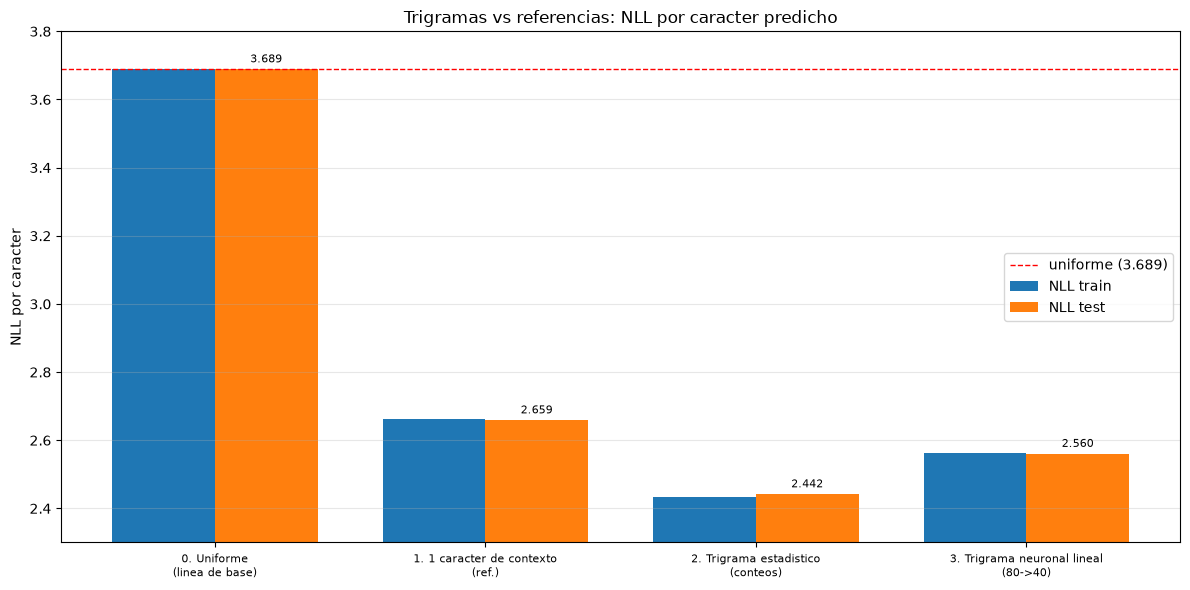

In [35]:
# Grafico de barras comparando los modelos en train y test.
nombres = [r[0] for r in resultados]
tr_vals = [r[2] for r in resultados]
te_vals = [r[3] for r in resultados]
x = np.arange(len(nombres))          # posiciones de las barras en el eje x
ancho = 0.38

fig, ax = plt.subplots(figsize=(12, 6))
# Desplazamos cada grupo medio ancho a izquierda y derecha para que no se superpongan
ax.bar(x - ancho / 2, tr_vals, ancho, label='NLL train')
ax.bar(x + ancho / 2, te_vals, ancho, label='NLL test')
ax.axhline(nll_uniforme, color='red', linestyle='--', linewidth=1,
           label=f'uniforme ({nll_uniforme:.3f})')
ax.set_xticks(x)
# Partimos las etiquetas en dos lineas para que entren
ax.set_xticklabels([n.replace(' (', '\n(') for n in nombres], fontsize=8)
ax.set_ylabel('NLL por caracter')
ax.set_title('Trigramas vs referencias: NLL por caracter predicho')
ax.set_ylim(2.3, 3.8)                # zoom: las diferencias son de decimas
ax.legend(); ax.grid(axis='y', alpha=0.3)

# Escribimos el valor exacto de test encima de cada barra
for xi, v in zip(x, te_vals):
    ax.text(xi + ancho / 2, v + 0.02, f'{v:.3f}', ha='center', fontsize=8)

plt.tight_layout()
plt.show()

### 11.1 Evolución de la pérdida durante el entrenamiento

Graficamos la pérdida de cada iteración del modelo neuronal. Como es la pérdida de un **mini-lote** (4.096 ejemplos al azar), es naturalmente **ruidosa**: cada lote es un poco distinto. Para ver la tendencia aplicamos una **media móvil**: reemplazamos cada punto por el promedio de los `w` puntos anteriores. Mostramos las dos cosas, la curva cruda tenue y la suavizada encima.

Qué buscar en el gráfico:

- La curva arranca en $\approx 3.69$ (el modelo no sabe nada: softmax casi uniforme).
- El **escalón** hacia el final es el momento en que bajamos el learning rate a `lr/10`: el ruido se reduce de golpe y la curva se afina.
- Que se **aplane** indica convergencia. Si siguiera bajando, convendría entrenar más.
- Las líneas horizontales punteadas son las referencias teóricas. La distancia que queda entre la curva y el trigrama estadístico **no** se cierra entrenando más: es la limitación estructural del modelo aditivo.

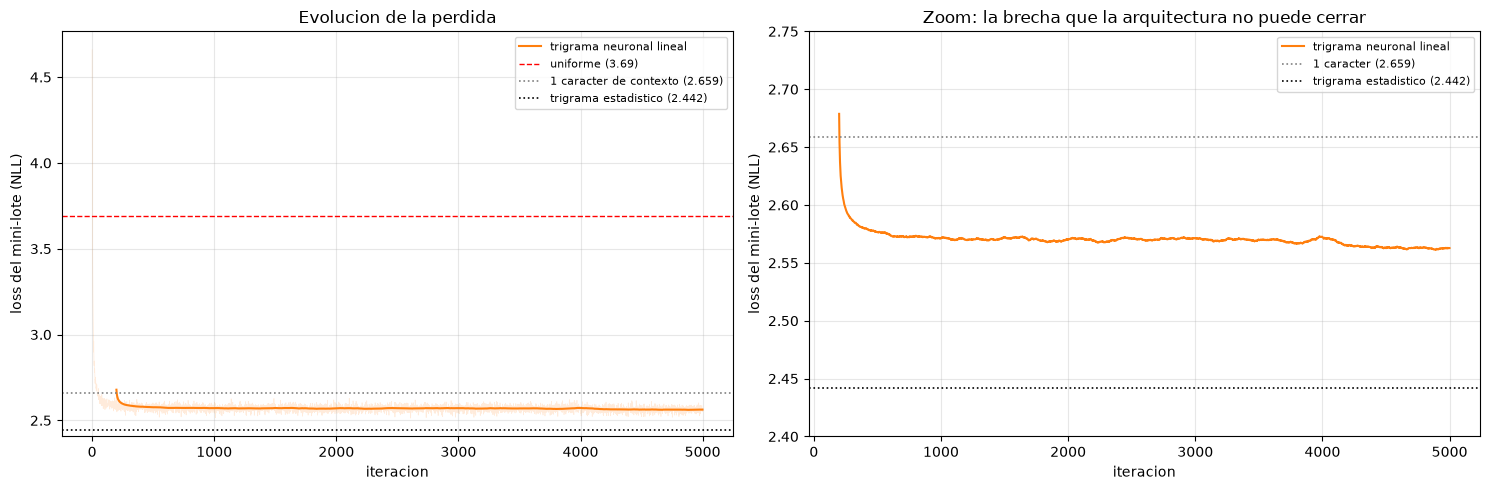

La curva se aplana bien por encima del trigrama estadistico.
Esa distancia es estructural, no un problema de entrenamiento.


In [36]:
def media_movil(x, w=100):
    """Media movil de ventana w: suaviza una serie ruidosa para ver la tendencia.

    np.convolve con un kernel de 1/w promedia cada punto con sus w-1 vecinos anteriores.
    mode='valid' descarta los bordes incompletos, asi que la salida tiene w-1 puntos menos.
    """
    if len(x) < w:
        return np.array(x)
    return np.convolve(x, np.ones(w) / w, mode='valid')


fig, axes = plt.subplots(1, 2, figsize=(15, 5))

suave = media_movil(historial, 200)

# --- Izquierda: la curva completa ---
axes[0].plot(historial, color='tab:orange', alpha=0.15, linewidth=0.5)          # crudo
axes[0].plot(np.arange(len(suave)) + 199, suave, color='tab:orange',
             label='trigrama neuronal lineal')                                  # suavizado
axes[0].axhline(nll_uniforme, color='red', linestyle='--', linewidth=1,
                label=f'uniforme ({nll_uniforme:.2f})')
axes[0].axhline(marg_test, color='gray', linestyle=':', linewidth=1.2,
                label=f'1 caracter de contexto ({marg_test:.3f})')
axes[0].axhline(tri_stat_test, color='black', linestyle=':', linewidth=1.2,
                label=f'trigrama estadistico ({tri_stat_test:.3f})')
axes[0].set_xlabel('iteracion'); axes[0].set_ylabel('loss del mini-lote (NLL)')
axes[0].set_title('Evolucion de la perdida'); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)

# --- Derecha: zoom en la zona de convergencia ---
axes[1].plot(np.arange(len(suave)) + 199, suave, color='tab:orange',
             label='trigrama neuronal lineal')
axes[1].axhline(marg_test, color='gray', linestyle=':', linewidth=1.2,
                label=f'1 caracter ({marg_test:.3f})')
axes[1].axhline(tri_stat_test, color='black', linestyle=':', linewidth=1.2,
                label=f'trigrama estadistico ({tri_stat_test:.3f})')
axes[1].set_ylim(2.40, 2.75)      # zoom: aca se ve la brecha que queda sin cerrar
axes[1].set_xlabel('iteracion'); axes[1].set_ylabel('loss del mini-lote (NLL)')
axes[1].set_title('Zoom: la brecha que la arquitectura no puede cerrar')
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print('La curva se aplana bien por encima del trigrama estadistico.')
print('Esa distancia es estructural, no un problema de entrenamiento.')

## 12. Generando nombres con el modelo neuronal

La generación autorregresiva neuronal sigue los mismos pasos que la del modelo estadístico, pero sacando la distribución de la red:

1. Empezar con los dos marcadores: `(c1, c2) = ('*', '*')`.
2. Calcular el **forward pass** con ese contexto → 40 logits.
3. Aplicar **softmax** → distribución de probabilidad sobre los 40 caracteres.
4. **Muestrear** con `torch.multinomial()`.
5. Incorporar el caracter generado al contexto y **desplazar la ventana**: `(c1, c2) = (c2, nuevo)`.
6. Repetir hasta generar `'*'` o alcanzar `max_len`.

**¿Qué hace `torch.multinomial(probs, num_samples=1)`?** Sortea un índice respetando la distribución `probs`: si `probs[7] = 0.3`, ese índice sale el 30% de las veces. Es el equivalente en PyTorch de `np.random.choice(..., p=probs)` que usamos en el modelo estadístico.

**¿Por qué muestrear y no tomar el `argmax`?** Porque el `argmax` (quedarse siempre con el caracter más probable) es **determinista**: generaría *siempre el mismo nombre*. Muestrear es lo que le da variedad al modelo, y además es lo honesto: estamos sacando muestras de la distribución que el modelo aprendió, que es justo lo que un modelo generativo debe hacer.

In [37]:
def generar_trigrama_neuronal(forward, cantidad=10, max_len=40, seed=0):
    """Genera nombres con el modelo NEURONAL de trigramas.

    forward  : funcion (idx_c1, idx_c2) -> logits (1, 40)
    cantidad : cuantos nombres generar
    max_len  : corte de seguridad para no generar nombres infinitos
    """
    g = torch.Generator().manual_seed(seed)    # semilla propia -> reproducible
    nombres = []

    with torch.no_grad():                      # generar no requiere gradientes
        for _ in range(cantidad):
            out = []
            i1, i2 = 0, 0                      # indice 0 = '*' : arrancamos con los DOS marcadores

            for _ in range(max_len):
                # 1) forward pass con el contexto actual (un lote de 1 ejemplo)
                logits = forward(torch.tensor([i1]), torch.tensor([i2]))   # (1, 40)

                # 2) softmax -> probabilidades. dim=1 normaliza a lo largo de las 40 clases.
                probs = F.softmax(logits, dim=1)                           # (1, 40)

                # 3) muestreamos un indice respetando la distribucion
                nuevo = torch.multinomial(probs, num_samples=1, replacement=True,
                                          generator=g).item()

                if nuevo == 0:                 # sorteamos '*' -> fin de la palabra
                    break

                out.append(itoc[nuevo])
                i1, i2 = i2, nuevo             # DESPLAZAMOS la ventana de dos caracteres

            nombres.append(''.join(out))
    return nombres


nombres_neur = generar_trigrama_neuronal(forward_lineal, 10, seed=0)

print('=== 10 nombres del MODELO 2 (trigrama neuronal lineal) ===')
for n in nombres_neur:
    print(' ', n)

=== 10 nombres del MODELO 2 (trigrama neuronal lineal) ===
  se
  bandouchemorn
  fo bonatswaluborborsvos da najin
  oano
  alingonzw
  ain
  giny
  hougllongwanattewajiacinardo da
  rapksas
  wasartich


In [38]:
# Comparamos los nombres de los dos modelos lado a lado.
print('=' * 56)
print('10 NOMBRES GENERADOS POR CADA MODELO')
print('=' * 56)
print(f"{'1. trigrama estadistico':<26} | {'2. trigrama neuronal':<26}")
print('-' * 56)
for a, b in zip(nombres_stat, nombres_neur):
    print(f'{a[:26]:<26} | {b[:26]:<26}')
print('=' * 56)

10 NOMBRES GENERADOS POR CADA MODELO
1. trigrama estadistico    | 2. trigrama neuronal      
--------------------------------------------------------
mookendruishita            | se                        
assovoaqan vilio k5kkhuman | bandouchemorn             
poia deava claihach        | fo bonatswaluborborsvos da
cer                        | oano                      
savey-sai fain             | alingonzw                 
plak                       | ain                       
mullana                    | giny                      
nas                        | hougllongwanattewajiacinar
perverne                   | rapksas                   
wessbunterosauren          | wasartich                 


In [39]:
# Medida objetiva de la calidad de lo generado: la NLL que el modelo estadistico
# (el mas fuerte de los dos) le asigna a los nombres de cada modelo.
# No es una metrica perfecta, pero da una senal cuantitativa de cuan "plausibles" son.
print('NLL que el trigrama estadistico le asigna a los nombres generados:')
print('(mas bajo = los nombres se parecen mas a ciudades reales)')
print()
for nombre, lista in [('1. trigrama estadistico', nombres_stat),
                      ('2. trigrama neuronal', nombres_neur)]:
    # Convertimos los nombres generados en tripletas y medimos su NLL
    gx1, gx2, gy = build_trigramas(lista)
    v = nll_trigrama(trigram_prob, gx1, gx2, gy)
    print(f'  {nombre:<26}: {v:.4f}')

# Referencia: la NLL de nombres REALES que el modelo nunca vio
rx1, rx2, ry = build_trigramas(test_names[:1000])
print()
print(f'  {"nombres reales (test)":<26}: {nll_trigrama(trigram_prob, rx1, rx2, ry):.4f}  <- referencia')

NLL que el trigrama estadistico le asigna a los nombres generados:
(mas bajo = los nombres se parecen mas a ciudades reales)

  1. trigrama estadistico   : 2.4820
  2. trigrama neuronal      : 2.7163

  nombres reales (test)     : 2.4317  <- referencia


## 13. Verificación final

Antes de cerrar, revisamos sistemáticamente todos los criterios de corrección:

1. Las formas de **todos** los tensores.
2. Que **cada distribución de probabilidad sume 1**, en el modelo estadístico y en el neuronal.
3. Que **no haya valores `NaN` ni infinitos** en los parámetros ni en las pérdidas.
4. Que los conjuntos de train y test sean **disjuntos**.
5. Que los dos modelos sean **mejores que el modelo uniforme**.

In [40]:
print('=' * 72)
print('VERIFICACION FINAL')
print('=' * 72)
ok = True

# --- 1) FORMAS DE LOS TENSORES ---
print('\n[1] Formas de los tensores')
chequeos_forma = [
    ('x1_tr',          x1_tr.shape,          (len(y_tr),)),
    ('x2_tr',          x2_tr.shape,          (len(y_tr),)),
    ('y_tr',           y_tr.shape,           (len(y_tr),)),
    ('x1_te',          x1_te.shape,          (len(y_te),)),
    ('trigram_count',  trigram_count.shape,  (nclasses, nclasses, nclasses)),
    ('trigram_prob',   trigram_prob.shape,   (nclasses, nclasses, nclasses)),
    ('marginal_prob',  marginal_prob.shape,  (nclasses, nclasses)),
    ('W',              W.shape,              (2 * nclasses, nclasses)),
    ('W.grad',         W.grad.shape,         (2 * nclasses, nclasses)),
]
for nombre, real, esperada in chequeos_forma:
    bien = tuple(real) == esperada
    ok &= bien
    print(f'  {"OK " if bien else "MAL"} {nombre:<16} {str(tuple(real)):<18} esperado {esperada}')

# --- 2) DISTRIBUCIONES DE PROBABILIDAD ---
print('\n[2] Las distribuciones suman 1')
s_tri = trigram_prob.sum(axis=2)        # (40, 40): una suma por contexto
s_mar = marginal_prob.sum(axis=1)       # (40,)
for nombre, s in [('trigram_prob (1600 contextos)', s_tri),
                  ('marginal_prob (40 filas)', s_mar)]:
    bien = bool(np.allclose(s, 1.0))
    ok &= bien
    print(f'  {"OK " if bien else "MAL"} {nombre:<32} {s.size:>5} distribuciones, '
          f'desvio maximo respecto de 1: {np.abs(s - 1).max():.2e}')

# El softmax del modelo neuronal tambien debe sumar 1
with torch.no_grad():
    p = F.softmax(forward_lineal(x1_tr[:500], x2_tr[:500]), dim=1)
    s = p.sum(dim=1)
    bien = bool(torch.allclose(s, torch.ones_like(s), atol=1e-5))
    ok &= bien
    print(f'  {"OK " if bien else "MAL"} softmax del modelo neuronal      500 distribuciones, '
          f'desvio maximo: {(s - 1).abs().max().item():.2e}')

# --- 3) SIN NaN NI INFINITOS ---
print('\n[3] Sin NaN ni valores infinitos')
# torch.isfinite: False donde hay nan, inf o -inf
for nombre, t in [('W', W), ('W.grad', W.grad)]:
    bien = bool(torch.isfinite(t).all())
    ok &= bien
    print(f'  {"OK " if bien else "MAL"} {nombre:<10} todos finitos  (rango [{t.min():.4f}, {t.max():.4f}])')

for nombre, arr in [('trigram_prob', trigram_prob), ('marginal_prob', marginal_prob)]:
    bien = bool(np.isfinite(arr).all())
    ok &= bien
    print(f'  {"OK " if bien else "MAL"} {nombre:<10} todos finitos')

for nombre, v in [('NLL trigrama estad.', tri_stat_test), ('NLL trigrama neur.', tri_neur_test),
                  ('NLL 1 caracter', marg_test)]:
    bien = bool(np.isfinite(v))
    ok &= bien
    print(f'  {"OK " if bien else "MAL"} {nombre:<22} = {v:.4f} (finita)')

bien = bool(np.isfinite(historial).all())
ok &= bien
print(f'  {"OK " if bien else "MAL"} historial de entrenamiento: {len(historial)} iteraciones, ninguna NaN/inf')

# --- 4) TRAIN Y TEST DISJUNTOS ---
print('\n[4] Particiones disjuntas')
bien = len(set(train_names) & set(test_names)) == 0
ok &= bien
print(f'  {"OK " if bien else "MAL"} ningun nombre esta en train y en test a la vez')
bien = len(y_tr) == sum(len(d) + 1 for d in train_names)
ok &= bien
print(f'  {"OK " if bien else "MAL"} cantidad de ejemplos de train = suma de (longitud + 1)')

# --- 5) LOS MODELOS SUPERAN LA LINEA DE BASE ---
print('\n[5] Los dos modelos superan la linea de base uniforme')
for nombre, v in [('trigrama estadistico', tri_stat_test), ('trigrama neuronal', tri_neur_test)]:
    bien = v < nll_uniforme
    ok &= bien
    print(f'  {"OK " if bien else "MAL"} {nombre:<22} {v:.4f} < {nll_uniforme:.4f}')

print()
print('=' * 72)
print('RESULTADO:', 'TODAS LAS VERIFICACIONES PASARON' if ok else 'HAY VERIFICACIONES QUE FALLARON')
print('=' * 72)
assert ok, 'alguna verificacion fallo'

VERIFICACION FINAL

[1] Formas de los tensores
  OK  x1_tr            (942116,)          esperado (942116,)
  OK  x2_tr            (942116,)          esperado (942116,)
  OK  y_tr             (942116,)          esperado (942116,)
  OK  x1_te            (104713,)          esperado (104713,)
  OK  trigram_count    (40, 40, 40)       esperado (40, 40, 40)
  OK  trigram_prob     (40, 40, 40)       esperado (40, 40, 40)
  OK  marginal_prob    (40, 40)           esperado (40, 40)
  OK  W                (80, 40)           esperado (80, 40)
  OK  W.grad           (80, 40)           esperado (80, 40)

[2] Las distribuciones suman 1
  OK  trigram_prob (1600 contextos)     1600 distribuciones, desvio maximo respecto de 1: 2.22e-16
  OK  marginal_prob (40 filas)            40 distribuciones, desvio maximo respecto de 1: 2.22e-16
  OK  softmax del modelo neuronal      500 distribuciones, desvio maximo: 2.38e-07

[3] Sin NaN ni valores infinitos
  OK  W          todos finitos  (rango [-5.5186, 5.806

In [41]:
# Resumen numerico final: la respuesta a la pregunta del experimento.
print('=' * 76)
print('CONCLUSION DEL EXPERIMENTO')
print('=' * 76)
print()
print('Pregunta: baja la NLL al usar DOS caracteres de contexto en lugar de UNO?')
print()
print(f'  1 caracter de contexto            : {marg_test:.4f}')
print(f'  2 caracteres, trigrama estadistico: {tri_stat_test:.4f}   ({marg_test - tri_stat_test:+.4f} nats)')
print(f'  2 caracteres, trigrama neuronal   : {tri_neur_test:.4f}   ({marg_test - tri_neur_test:+.4f} nats)')
print()
print('RESPUESTA: si. El contexto extra reduce la NLL de prueba en los dos modelos,')
print('medido sobre nombres que ninguno de los dos vio nunca.')
print()
print('--- pero la arquitectura importa ---')
disponible = marg_test - tri_stat_test     # toda la mejora que el contexto extra puede dar
capturada = marg_test - tri_neur_test      # la que el modelo lineal logra capturar
print(f'  mejora total disponible (hasta el optimo por conteo): {disponible:.4f} nats')
print(f'  capturada por el modelo neuronal lineal            : {capturada:.4f} nats '
      f'({100 * capturada / disponible:.1f}%)')
print(f'  le falta                                           : {disponible - capturada:.4f} nats')
print()
print('Esa parte que falta es exactamente el termino de interaccion que medimos en 10.3')
print('y que vale cero: el modelo aditivo no puede representarlo.')
print()
print('--- sobreajuste (brecha test - train) ---')
for nombre, par, tr, te in resultados[1:]:
    print(f'  {nombre:<40} {te - tr:+.4f}')

CONCLUSION DEL EXPERIMENTO

Pregunta: baja la NLL al usar DOS caracteres de contexto en lugar de UNO?

  1 caracter de contexto            : 2.6589
  2 caracteres, trigrama estadistico: 2.4419   (+0.2170 nats)
  2 caracteres, trigrama neuronal   : 2.5605   (+0.0984 nats)

RESPUESTA: si. El contexto extra reduce la NLL de prueba en los dos modelos,
medido sobre nombres que ninguno de los dos vio nunca.

--- pero la arquitectura importa ---
  mejora total disponible (hasta el optimo por conteo): 0.2170 nats
  capturada por el modelo neuronal lineal            : 0.0984 nats (45.3%)
  le falta                                           : 0.1186 nats

Esa parte que falta es exactamente el termino de interaccion que medimos en 10.3
y que vale cero: el modelo aditivo no puede representarlo.

--- sobreajuste (brecha test - train) ---
  1. 1 caracter de contexto (ref.)         -0.0050
  2. Trigrama estadistico (conteos)        +0.0094
  3. Trigrama neuronal lineal (80->40)     -0.0024


---

## 14. Conclusiones

### 14.1 Los resultados

| # | Modelo | Parámetros | NLL train | NLL test | Brecha | Perplejidad |
|---|---|---|---|---|---|---|
| 0 | Uniforme | 0 | 3.6889 | 3.6889 | 0.0000 | 40.0 |
| 1 | 1 caracter de contexto *(referencia)* | 1.600 | 2.6638 | 2.6589 | -0.0050 | 14.3 |
| 2 | **Trigrama estadístico (conteos)** | 64.000 | 2.4325 | **2.4419** | +0.0094 | 11.5 |
| 3 | **Trigrama neuronal lineal (80→40)** | 3.200 | 2.5628 | 2.5605 | -0.0024 | 12.9 |

### 14.2 Respuesta a la pregunta del experimento

**Sí: usar dos caracteres de contexto en lugar de uno reduce la NLL, y la mejora generaliza.**

Medido siempre sobre nombres que el modelo nunca vio:

- **Trigrama estadístico:** 2.6589 → 2.4419, una mejora de **0.2170 nats**.
- **Trigrama neuronal lineal:** 2.6589 → 2.5605, una mejora de **0.0984 nats**.

El **mejor resultado** es el del **trigrama estadístico por conteos**, con NLL de prueba **2.4419**. En términos de perplejidad: el modelo uniforme duda entre **40** caracteres, con un solo caracter de contexto la duda baja a **14.3**, y con dos caracteres a **11.5**.

### 14.3 Los dos modelos reciben la misma información y no rinden igual

Este es el resultado que más vale la pena entender, porque no era obvio de antemano.

Los dos modelos de trigrama ven **exactamente los mismos dos caracteres** y los mismos datos. Sin embargo:

| Modelo de trigrama | NLL test | Por qué |
|---|---|---|
| Neuronal **lineal** | 2.5605 | aditivo: `logits = U[c1] + V[c2]`. **No puede** modelar interacciones |
| **Estadístico** | 2.4419 | una distribución libre por contexto: el óptimo alcanzable |

De toda la mejora que el segundo caracter puede aportar (**0.2170 nats**, la distancia entre el modelo de 1 caracter y el óptimo por conteo), **el modelo neuronal lineal capturó el 45.3%** y le quedaron **0.1186 nats** sin aprovechar.

Y ese faltante **no es un problema de entrenamiento**: entrenar más iteraciones no lo cierra. Es **estructural**, y lo medimos directamente. El término de interacción

$$I(c_1, c_2) = \text{logits}(c_1,c_2) - \text{logits}(c_1,*) - \text{logits}(*,c_2) + \text{logits}(*,*)$$

dio **cero** (salvo error de redondeo, ~$10^{-6}$) para todos los contextos que probamos. Esa cuenta aísla justamente la parte de la predicción que depende de la **combinación** de los dos caracteres, y en un modelo aditivo esa parte no existe.

En concreto: la forma `U[c1] + V[c2]` hace que la contribución de cada caracter sea independiente de la del otro. El modelo no puede decir *"después de `an` viene `d`"* sin decir también *"después de `a` + cualquier cosa viene `d`"*. El trigrama estadístico sí puede, porque guarda una distribución separada e independiente para cada uno de los 1.600 contextos.

> 🔑 **La lección:** el contexto extra es una condición *necesaria* pero no *suficiente*. Si la arquitectura no puede representar las interacciones entre los elementos del contexto, parte de la información adicional se desperdicia.

### 14.4 El costo: dispersión de datos y sobreajuste

El trigrama paga un precio por su capacidad extra, y se puede medir:

- El tensor de conteos tiene **64.000** celdas, pero solo **18.7%** se observaron alguna vez. La enorme mayoría de las combinaciones de tres caracteres **nunca aparece** en las ~90.000 entradas de entrenamiento.
- De los contextos que sí se observaron, **30%** tienen menos de 40 observaciones, que son menos datos que los 40 números que habría que estimar con ellos.
- La **brecha train/test** crece con la cantidad de parámetros: -0.0050 con un caracter de contexto contra +0.0094 en el trigrama estadístico. Esa brecha *es* el sobreajuste, medido.

Por eso el **suavizado** deja de ser un detalle y se vuelve imprescindible: sin él, el 81% de las celdas valdría 0 y un solo trigrama no visto en test mandaría la NLL a infinito.

El barrido de $\alpha$ mostró el fenómeno con claridad: al reducir el suavizado, la NLL de train baja **siempre** (el modelo se pega cada vez más a lo que vio), pero la de test toca un mínimo y después **empeora**. Ese es el *bias-variance trade-off* en su forma más pura.

Vale notar que **el trigrama no sobreajustó lo suficiente como para perder**: su NLL de test mejora de todos modos. Con ~90.000 entradas hay datos suficientes para que el contexto extra pague. Si el dataset fuera 100 veces más chico, el resultado podría haberse invertido perfectamente — y con un modelo de 4-gramas ($40^4 = 2.560.000$ celdas) la dispersión sería mucho más severa.

### 14.5 Hacia dónde sigue esto

Hay dos caminos naturales a partir de acá, y los dos salen de las limitaciones que acabamos de medir:

**1. Arreglar la arquitectura neuronal.** El problema del modelo lineal es que `logits = U[c1] + V[c2]` es aditivo. Si entre la entrada y la salida metemos una **capa oculta con una función de activación no lineal** (por ejemplo `tanh`), la aditividad se rompe: como $\tanh(u+v) \neq \tanh(u) + \tanh(v)$, el efecto de $c_1$ pasa a depender del valor de $c_2$. Una neurona oculta puede entonces aprender a activarse **solo** ante una combinación específica, que es justo lo que al modelo lineal le falta.

**2. Escalar a más contexto.** El modelo estadístico no escala: un 4-grama necesitaría un tensor de $40^4$ y un 5-grama de $40^5$. La red neuronal escala mejor, pero concatenar one-hot tampoco escala del todo (con 5 caracteres de contexto la entrada tendría 200 posiciones y la dispersión reaparecería, ahora en los pesos). La solución a eso es lo que viene después en makemore: en lugar de un one-hot de 40 posiciones por caracter, aprender un vector **denso** y chico por caracter (un ***embedding***), de modo que caracteres con comportamiento parecido terminen con vectores parecidos y el modelo pueda **compartir aprendizaje** entre ellos.

---

### 📋 Resumen de conceptos aplicados

| Concepto | Dónde apareció |
|---|---|
| **Probabilidad condicional** | $P(c_3 \mid c_1, c_2)$ estimada como $\#(c_1,c_2,c_3) / \#(c_1,c_2,\cdot)$ |
| **Hipótesis de Markov** | truncar la historia a los últimos 2 caracteres (orden 2) |
| **Tensores y dimensiones** | el tensor `(40,40,40)` como pila de 40 tablas; formas verificadas en cada paso |
| **Normalización por eje** | `sum(axis=2, keepdims=True)`: por qué el eje importa y qué hace `keepdims` |
| **One-Hot Encoding** | `F.one_hot`: caracteres como categorías sin orden ni magnitud |
| **Concatenación de One-Hot** | `torch.cat([...], dim=1)`: dos contextos → 80 entradas con dos unos |
| **Neuronas y capas** | `W` de `(80,40)` = 40 neuronas de 80 entradas; cada columna es una neurona |
| **Logits** | la salida cruda de la red, interpretada como log-conteos |
| **Softmax** | $e^{z_i} / \sum_j e^{z_j}$: logits → distribución de probabilidad |
| **Negative Log Likelihood** | $-\frac{1}{n}\sum \log P(c_i \mid c_1, c_2)$, la métrica de todo el notebook |
| **Cross-Entropy** | lo mismo que la NLL con etiquetas de una sola clase; verificado numéricamente |
| **Estabilidad numérica** | `F.cross_entropy` sobrevive a logits ×100 donde el `exp()` manual desborda |
| **Backpropagation** | `loss.backward()`: regla de la cadena hacia atrás sobre el grafo de autograd |
| **Descenso por gradiente** | `W.data += -lr * W.grad`, con los gradientes limpiados en cada paso |
| **Learning rate** | 50, justificado por lo chicos que son los gradientes del one-hot, con decaimiento |
| **Mini-lotes (SGD)** | gradiente estimado sobre 4.096 ejemplos al azar por iteración |
| **Regularización** | Laplace smoothing como *prior*; barrido de $\alpha$ y su efecto en test |
| **Generalización / sobreajuste** | split por nombre, brecha train/test, mínimo de la curva de test |
| **Data leakage** | nombres repetidos: por qué hay que partir por nombre único |
| **Límite de expresividad** | el término de interacción nulo del modelo aditivo |
| **Generación autorregresiva** | ventana de dos caracteres desplazándose, `torch.multinomial`, corte por `max_len` |